# Phase 3 showcase: is the uncertainty *useful*?

Four experiments on top of the Phase 3 models, each producing a figure for the final report or client demo.

| | Experiment | Question it answers | GPU time |
|---|---|---|---|
| A | **Adaptive uncertainty** (`--posterior env`) | Can the noise level react to each atom's local geometry, not just its element? | ~2 h (one 200-epoch run) |
| B | **Out-of-distribution test** | Does predicted uncertainty rise on rare geometries and on molecules the model never saw? | ~5 min per model |
| C | **Uncertainty-guided active learning** | Does labelling the most uncertain frames beat labelling random ones? (fewer DFT calculations) | ~30–40 min |
| D | **MD early warning + 3D viewer** | When a simulation drifts somewhere unphysical, does the uncertainty warn first? | ~2 min |

B and D use the checkpoints you already trained (in `phase3_runs` on Drive), so you can run them straight away.
**Runtime → Change runtime type → GPU** before starting.

## 1. Repo and data (all molecules, needed for the out-of-distribution test)

In [4]:
import os, sys, glob, json
!apt-get -qq install git-lfs > /dev/null
!git lfs install
REPO = "/content/HydrogenProductionMaterials_Discovery"
if not os.path.exists(REPO):
    !git clone https://github.com/AlexTanui/HydrogenProductionMaterials_Discovery {REPO}
%cd {REPO}
!git lfs pull --include="data/bronze/md17/*"
!python -m ml.data.preprocessing
GOLD = f"{REPO}/data/gold/md17"
print(sorted(os.listdir(GOLD)))

Updated Git hooks.
Git LFS initialized.
/content/HydrogenProductionMaterials_Discovery

Bronze dir: /content/HydrogenProductionMaterials_Discovery/data/bronze/md17
Source                       Molecule       Theory   Status
------------------------------------------------------------------------------
md17_ethanol.npz             ethanol        dft      OK -> ethanol_dft.npz (444074 train configs)
ethanol_ccsd_t.zip           ethanol        ccsd_t   OK -> ethanol_ccsd_t.npz (889 train configs)
benzene2018_dft.npz          benzene        dft      OK -> benzene_dft.npz (39890 train configs)
azobenzene_dft.npz           azobenzene     dft      OK -> azobenzene_dft.npz (79999 train configs)
paracetamol_dft.npz          paracetamol    dft      OK -> paracetamol_dft.npz (85192 train configs)
aspirin_ccsd.zip             aspirin        ccsd     OK -> aspirin_ccsd.npz (889 train configs)
malonaldehyde_ccsd_t.zip     malonaldehyde  ccsd_t   OK -> malonaldehyde_ccsd_t.npz (889 train configs)
tol

In [5]:
from google.colab import drive
drive.mount("/content/drive")
RUNS = "/content/drive/MyDrive/phase3_runs"        # where your Phase 3 checkpoints are
SHOW = "/content/drive/MyDrive/phase3_showcase"    # figures and results from this notebook
os.makedirs(SHOW, exist_ok=True)
print("checkpoints:", [os.path.basename(p) for p in sorted(glob.glob(f"{RUNS}/*.pt"))])

Mounted at /content/drive
checkpoints: ['gold_ethanol_dft_graph-both-env_seed1.pt', 'gold_ethanol_dft_graph-both_seed1.pt', 'gold_ethanol_dft_graph-edge_seed1.pt', 'gold_ethanol_dft_graph-node_seed1.pt']


## 2. Code (+ quick self-test, ~2 min)

In [6]:
%%writefile /content/stochastic_md17.py
"""Phase 1 / 2 / 3 on one PaiNN backbone, one data path and one training loop.

  --model painn   Phase 1: deterministic PaiNN.
  --model blip    Phase 2: BLIP weight-space stochasticity (unchanged from
                  Blip_model_building.ipynb).
  --model graph   Phase 3: graph-space stochasticity. Weights are ordinary
                  deterministic layers; the noise sits on representations:
                    --stoch node   node features after every update block
                    --stoch edge   the edge filter in every message block
                    --stoch both   both of the above (RQ3 ablation)

Phase 3 reuses BLIP's noise family, posterior network and KL so that the
only thing that changes between Phase 2 and Phase 3 is WHERE the noise lives:

  BLIP (weights):    w  ~ N(theta, alpha*theta^2)          per row
  Phase 3 (reps):    h' = h * (1 + sqrt(alpha) * eps),  eps ~ N(0, 1)
                     i.e. h' ~ N(h, alpha*h^2)            per node / edge

alpha comes from the same invariant posterior E_psi (embedding of Z for
nodes, |r_ij|^2 for edges) and is regularised by the same
KL[N(x, a x^2) || N(0, c x^2)], c = p/(1-p), times beta.

Symmetry: every perturbed quantity is either an invariant scalar (s, the
edge filter) or a PaiNN vector feature v multiplied by one scalar per
channel shared across x/y/z. So E stays invariant and F = -dE/dR stays
equivariant for every noise draw, and is the exact gradient of that draw's
energy with alpha held fixed (alpha is computed from detached positions, as in
official BLIP).

--posterior env (adaptive, opt-in) lets the node noise level depend on each
atom's local geometry instead of its element alone; see Posterior. tests_stochastic_md17.py
checks this numerically.
"""
from __future__ import annotations

import argparse
import copy
import csv
import json
import math
import os
import sys
import tarfile
import time
import urllib.request

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

KCAL_TO_MEV = 43.3641  # 1 kcal/mol = 43.3641 meV

# Data
RMD17_URL = "https://figshare.com/ndownloader/files/23950376"  # rmd17.tar.bz2
MD17_URL = "http://www.quantum-machine.org/gdml/data/npz/md17_{}.npz"
RMD17_NAMES = {"aspirin", "azobenzene", "benzene", "ethanol", "malonaldehyde",
               "naphthalene", "paracetamol", "salicylic", "toluene", "uracil"}


def _download(url, path):
    """Download to path.part, then rename - so a failed or empty download never
    leaves a file behind that later runs mistake for real data."""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    print(f"Downloading {url} -> {path}")
    tmp = path + ".part"
    try:
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=120) as r, open(tmp, "wb") as f:
            while chunk := r.read(1 << 20):
                f.write(chunk)
        if os.path.getsize(tmp) < 1024:
            raise OSError(f"server returned {os.path.getsize(tmp)} bytes, not the data file")
    except Exception as e:
        if os.path.exists(tmp):
            os.remove(tmp)
        raise SystemExit(
            f"Download failed: {url}\n  {type(e).__name__}: {e}\n"
            "For the team protocol use the repo's gold data instead of downloading:\n"
            "  --repo-dir <path to HydrogenProductionMaterials_Discovery> --molecule ethanol --theory dft\n"
            "or test the code offline with --synthetic.")
    os.replace(tmp, path)


def _drop_if_broken(path, min_bytes=1024):
    """Remove a leftover empty/truncated file from an earlier failed download."""
    if os.path.exists(path) and os.path.getsize(path) < min_bytes:
        print(f"removing broken file from an earlier failed download: {path}")
        os.remove(path)


def _check_not_lfs_pointer(path):
    with open(path, "rb") as f:
        head = f.read(64)
    if head.startswith(b"version https://git-lfs"):
        raise SystemExit(
            f"{path} is a Git LFS pointer, not the real data.\n"
            "Run `git lfs install && git lfs pull` inside the repository (or "
            "`scripts/download_bronze_data.sh`), then `python -m ml.data.preprocessing`.")


def stride_subset(n, size, seed):
    """Team rule from ml/training/train.py: fixed stride with a seeded offset."""
    if size is None or size <= 0 or size >= n:
        return np.arange(n)
    stride = n // size
    offset = int(np.random.default_rng(seed).integers(stride))
    return offset + stride * np.arange(size)


def load_gold(args):
    """Team gold file (HydrogenProductionMaterials_Discovery, data/gold/md17/
    {molecule}_{theory}.npz): z, R, E, F + train_idx/val_idx/test_idx, already
    in A and kcal/mol. The shipped contiguous-block splits are used as is,
    never re-split; optional subsets use the team's stride rule."""
    path = args.gold
    if path is None:
        path = os.path.join(args.repo_dir, "data", "gold", "md17", f"{args.molecule}_{args.theory}.npz")
    if not os.path.exists(path):
        raise SystemExit(
            f"gold file not found: {path}\n"
            "Inside the repository run:  git lfs pull  &&  python -m ml.data.preprocessing")
    _check_not_lfs_pointer(path)
    d = np.load(path, allow_pickle=True)
    for k in ("molecule", "theory"):
        if k in d.files:
            print(f"gold {k}: {d[k]}")
    tr = d["train_idx"][stride_subset(len(d["train_idx"]), args.train_subset, args.subset_seed)]
    va = d["val_idx"][stride_subset(len(d["val_idx"]), args.val_subset, args.subset_seed)]
    te = d["test_idx"][stride_subset(len(d["test_idx"]), args.test_subset, args.subset_seed)]
    return (d["z"].astype(np.int64), d["R"].astype(np.float32), d["E"].reshape(-1).astype(np.float64),
            d["F"].astype(np.float32), (tr, va, te))


def load_md17(args):
    """Returns z (N,), R (M,N,3) [A], E (M,) [kcal/mol], F (M,N,3) [kcal/mol/A],
    and (pool_idx, test_idx); pool_idx is the 1000-structure training budget."""
    rng = np.random.default_rng(args.seed)
    if args.synthetic:
        return make_synthetic(rng)

    split = None
    if args.npz:
        _check_not_lfs_pointer(args.npz)
        d = np.load(args.npz)
    elif args.dataset == "rmd17":
        mol = "salicylic" if args.molecule.startswith("salicylic") else args.molecule
        if mol not in RMD17_NAMES:
            raise ValueError(f"unknown rMD17 molecule '{mol}', choose from {sorted(RMD17_NAMES)}")
        root = os.path.join(args.data_dir, "rmd17")
        npz = os.path.join(root, "npz_data", f"rmd17_{mol}.npz")
        if not os.path.exists(npz):
            arc = os.path.join(args.data_dir, "rmd17.tar.bz2")
            _drop_if_broken(arc)
            if not os.path.exists(arc):
                _download(RMD17_URL, arc)
            try:
                with tarfile.open(arc) as t:
                    t.extractall(args.data_dir)
            except tarfile.TarError as e:
                os.remove(arc)
                raise SystemExit(f"{arc} is not a valid rMD17 archive ({e}); removed it, run again to re-download")
        d = np.load(npz)
        sp = os.path.join(root, "splits")
        split = (np.loadtxt(os.path.join(sp, f"index_train_0{args.split}.csv"), dtype=int),
                 np.loadtxt(os.path.join(sp, f"index_test_0{args.split}.csv"), dtype=int))
    else:
        npz = os.path.join(args.data_dir, f"md17_{args.molecule}.npz")
        _drop_if_broken(npz)
        if not os.path.exists(npz):
            _download(MD17_URL.format(args.molecule), npz)
        d = np.load(npz)

    if "nuclear_charges" in d.files:   # rMD17 format
        z, R, E, Fo = d["nuclear_charges"], d["coords"], d["energies"], d["forces"]
    else:                              # MD17 / sGDML format
        z, R, E, Fo = d["z"], d["R"], d["E"], d["F"]
    E = np.asarray(E).reshape(-1)
    if split is None:
        perm = rng.permutation(len(E))
        split = (perm[:1000], perm[1000:1000 + args.n_test])
    return (z.astype(np.int64), R.astype(np.float32), E.astype(np.float64),
            Fo.astype(np.float32), split)


def make_synthetic(rng, n=1300, natoms=9):
    """Toy molecule with a Morse pair potential, for offline testing."""
    z = rng.choice([1, 6, 8], natoms)
    base = rng.normal(0, 1.2, (natoms, 3))
    R = base[None] + rng.normal(0, 0.08, (n, natoms, 3))
    Rt = torch.tensor(R, requires_grad=True)
    eye = torch.eye(natoms, dtype=Rt.dtype)
    d = torch.cdist(Rt, Rt) + eye
    d0 = torch.cdist(torch.tensor(base[None]), torch.tensor(base[None])) + eye
    E = (20.0 * (1 - torch.exp(-1.5 * (d - d0))) ** 2 * (1 - eye)).sum((1, 2)) / 2
    Fo = -torch.autograd.grad(E.sum(), Rt)[0]
    perm = rng.permutation(n)
    return (z.astype(np.int64), R.astype(np.float32), E.detach().numpy().astype(np.float64),
            Fo.numpy().astype(np.float32), (perm[:1000], perm[1000:]))


class Batch:
    """MD17 frames of one molecule share their atoms, so batching is a reshape;
    the radius graph is rebuilt for every batch."""

    def __init__(self, z, R, E, Fo, cutoff, device):
        B, N, _ = R.shape
        self.n_graphs, self.n_atoms = B, N
        self.z = z.repeat(B).to(device)
        self.pos = R.reshape(B * N, 3).to(device).requires_grad_(True)
        self.E = E.to(device)
        self.F = Fo.reshape(B * N, 3).to(device)
        self.batch = torch.arange(B, device=device).repeat_interleave(N)
        with torch.no_grad():
            m = (torch.cdist(R, R) < cutoff) & ~torch.eye(N, dtype=torch.bool)
            b, i, j = m.nonzero(as_tuple=True)
        self.dst = (b * N + i).to(device)  # receiving atom i
        self.src = (b * N + j).to(device)  # neighbour j (both directions present)


def make_batches(idx, data, bs, shuffle, rng, cutoff, device):
    z, R, E, Fo = data
    idx = rng.permutation(idx) if shuffle else idx
    for k in range(0, len(idx), bs):
        ii = idx[k:k + bs]
        yield Batch(z, R[ii], E[ii], Fo[ii], cutoff, device)


# BLIP components
class BayesLinear(nn.Linear):
    """w ~ N(theta, alpha * theta^2) via the local reparameterisation trick.
    alpha: (rows, 1) tensor, or None for the deterministic (MAP) pass."""

    def forward(self, x, alpha=None):
        mean = F.linear(x, self.weight, self.bias)
        if alpha is None:
            return mean
        var = alpha * F.linear(x.pow(2), self.weight.pow(2))
        return mean + torch.sqrt(var + 1e-18) * torch.randn_like(mean)


class KL:
    """KL[N(theta, a theta^2) || N(0, c theta^2)], c = p/(1-p), averaged over
    all rows and layers, times beta (official blip/bayes/kl.py)."""

    def __init__(self, p=0.5, beta=10.0):
        self.c, self.logc, self.beta = p / (1 - p), math.log(p / (1 - p)), beta

    def __call__(self, alphas):
        return self.beta * (0.5 * ((alphas + 1) / self.c + self.logc - torch.log(alphas) - 1)).mean()


class Posterior(nn.Module):
    """Invariant inference network E_psi.

    node_input="z" (default, official PosteriorModelPaiNN): node head sees only an
    embedding of the atom's element Z, so every C (or O, or H) gets the same
    noise level whatever its geometry. Edge head on ||r_i - r_j||^2.

    node_input="env" (adaptive, opt-in): node head also sees the atom's local
    chemical environment - an element-resolved radial density
        g_i[k, m] = sum_j fcut(d_ij) * exp(-(d_ij - mu_k)^2 / 2w^2) * e_m(Z_j)
    (Gaussian distance bins mu_k x a small learned neighbour-element embedding
    e_m), log1p-compressed and layer-normalised. It is built from distances only,
    so alpha stays rotation/translation/permutation invariant, but now a
    stretched bond or a crowded atom can get more noise than a relaxed one.

    Positions are detached for alpha in both modes (as in official BLIP): forces
    are -dE/dR at fixed alpha."""

    def __init__(self, n_node, n_edge, hidden=64, n_layers=2, clamp_max_p=0.8, init_p=0.05,
                 node_input="z", cutoff=5.0, env_bins=16, env_elem=8):
        super().__init__()
        if node_input not in ("z", "env"):
            raise ValueError(f"node_input must be z | env, got {node_input!r}")
        self.node_input, self.cutoff = node_input, cutoff
        self.emb = nn.Embedding(100, hidden // 2, padding_idx=0)

        def mlp(i, o):
            layers, d = [], i
            for _ in range(n_layers - 1):
                layers += [nn.Linear(d, hidden), nn.SiLU()]
                d = hidden
            return nn.Sequential(*layers, nn.Linear(d, o))

        # A head with zero outputs is skipped (Phase 3 node-only / edge-only);
        # BLIP always has both, so its construction order and init are unchanged.
        env_dim = env_bins * env_elem if node_input == "env" else 0
        self.node = mlp(hidden // 2 + env_dim, n_node) if n_node else None
        self.edge = mlp(1, n_edge) if n_edge else None
        self.clamp_max_p = clamp_max_p
        if node_input == "env":  # created last, so the default ("z") init is unchanged
            self.env_elem = nn.Embedding(100, env_elem, padding_idx=0)
            self.register_buffer("env_mu", torch.linspace(0.0, cutoff, env_bins))
            self.env_width = cutoff / (env_bins - 1)
            self.env_norm = nn.LayerNorm(env_dim)
        # Start with small noise (p = init_p) so early training is stable; the
        # official ORB posterior does the same with a learned offset.
        logit = math.log(init_p / (1 - init_p))
        for head in (self.node, self.edge):
            if head is None:
                continue
            nn.init.zeros_(head[-1].weight)
            nn.init.constant_(head[-1].bias, logit)

    def _alpha(self, logits):
        p = logits.sigmoid().clamp(min=1e-6, max=self.clamp_max_p)
        return p / (1 - p)

    def environment(self, b):
        """Element-resolved radial density around each atom: (n_atoms, bins*elem)."""
        pos = b.pos.detach()
        d = (pos[b.src] - pos[b.dst]).norm(dim=-1)
        rbf = torch.exp(-((d[:, None] - self.env_mu) ** 2) / (2 * self.env_width ** 2))
        w = (rbf * cosine_cutoff(d, self.cutoff)[:, None])[:, :, None] * self.env_elem(b.z[b.src])[:, None, :]
        g = torch.zeros(b.z.shape[0], *w.shape[1:], device=w.device, dtype=w.dtype).index_add_(0, b.dst, w)
        g = g.flatten(1)
        return self.env_norm(torch.sign(g) * torch.log1p(g.abs()))

    def forward(self, b):
        node = edge = None
        if self.node is not None:
            h = self.emb(b.z)
            if self.node_input == "env":
                h = torch.cat([h, self.environment(b)], -1)
            node = self._alpha(self.node(h))
        if self.edge is not None:
            pos = b.pos.detach()
            r2 = (pos[b.src] - pos[b.dst]).pow(2).sum(-1, keepdim=True)
            edge = self._alpha(self.edge(r2))
        return node, edge



# PaiNN with BLIP layers
class PainnRBF(nn.Module):
    def __init__(self, n, cutoff):
        super().__init__()
        self.register_buffer("freq", torch.arange(1, n + 1) * math.pi / cutoff)

    def forward(self, d):
        return torch.sin(self.freq * d[:, None]) / d[:, None]


def cosine_cutoff(d, rc):
    return 0.5 * (torch.cos(d * math.pi / rc) + 1.0) * (d < rc)


class AlphaRouter:
    """Hands each Bayesian layer its own alpha column (official alpha hooks)."""

    def __init__(self):
        self.n = {"node": 0, "edge": 0}

    def new(self, domain):
        self.n[domain] += 1
        return domain, self.n[domain] - 1


def _a(alphas, slot):
    if alphas is None:
        return None
    domain, k = slot
    return alphas[domain][:, k:k + 1]


class Message(nn.Module):
    def __init__(self, F_, n_rbf, cutoff, router):
        super().__init__()
        self.phi1, self.phi2 = BayesLinear(F_, F_), BayesLinear(F_, 3 * F_)
        self.W = BayesLinear(n_rbf, 3 * F_)
        self.s_phi1, self.s_phi2 = router.new("node"), router.new("node")
        self.s_W = router.new("edge")
        self.F_, self.cutoff = F_, cutoff

    def forward(self, s, v, b, rbf, d, unit, al):
        phi = self.phi2(F.silu(self.phi1(s, _a(al, self.s_phi1))), _a(al, self.s_phi2))
        x = phi[b.src] * self.W(rbf, _a(al, self.s_W)) * cosine_cutoff(d, self.cutoff)[:, None]
        ds, dvv, dvs = torch.split(x, self.F_, -1)
        dv = v[b.src] * dvv[:, None] + dvs[:, None] * unit[..., None]
        s = s + torch.zeros_like(s).index_add_(0, b.dst, ds)
        v = v + torch.zeros_like(v).index_add_(0, b.dst, dv)
        return s, v


class Update(nn.Module):
    def __init__(self, F_, router):
        super().__init__()
        self.U = nn.Linear(F_, F_, bias=False)   # deterministic
        self.V = nn.Linear(F_, F_, bias=False)
        self.a1, self.a2 = BayesLinear(2 * F_, F_), BayesLinear(F_, 3 * F_)
        self.s_a1, self.s_a2 = router.new("node"), router.new("node")
        self.F_ = F_

    def forward(self, s, v, al):
        Uv, Vv = self.U(v), self.V(v)
        Vn = torch.sqrt(Vv.pow(2).sum(1) + 1e-8)
        a = self.a2(F.silu(self.a1(torch.cat([s, Vn], -1), _a(al, self.s_a1))), _a(al, self.s_a2))
        avv, asv, ass = torch.split(a, self.F_, -1)
        return s + asv * (Uv * Vv).sum(1) + ass, v + avv[:, None] * Uv


class BLIPPaiNN(nn.Module):
    def __init__(self, F_=128, n_layers=3, n_rbf=20, cutoff=5.0, bayesian=True,
                 posterior_hidden=64, posterior_layers=2, clamp_max_p=0.8, init_p=0.05,
                 posterior_input="z"):
        super().__init__()
        router = AlphaRouter()
        self.cutoff, self.bayesian = cutoff, bayesian
        self.emb = nn.Embedding(100, F_, padding_idx=0)
        self.rbf = PainnRBF(n_rbf, cutoff)
        self.msg = nn.ModuleList([Message(F_, n_rbf, cutoff, router) for _ in range(n_layers)])
        self.upd = nn.ModuleList([Update(F_, router) for _ in range(n_layers)])
        self.r1, self.r2 = BayesLinear(F_, F_ // 2), BayesLinear(F_ // 2, 1)
        self.s_r1, self.s_r2 = router.new("node"), router.new("node")
        self.n_alpha = dict(router.n)
        self.posterior = (Posterior(router.n["node"], router.n["edge"], posterior_hidden,
                                    posterior_layers, clamp_max_p, init_p,
                                    node_input=posterior_input, cutoff=cutoff) if bayesian else None)
        self.register_buffer("e_shift", torch.zeros(()))  # mean energy per atom
        self.register_buffer("scale", torch.ones(()))     # force RMS

    def alphas(self, b):
        node, edge = self.posterior(b)
        return {"node": node, "edge": edge}

    def forward(self, b, alphas=None, create_graph=False):
        """alphas=None -> deterministic MAP pass; dict -> one stochastic sample."""
        rij = b.pos[b.src] - b.pos[b.dst]
        d = torch.sqrt(rij.pow(2).sum(-1) + 1e-12)
        unit, rbf = rij / d[:, None], self.rbf(d)
        s = self.emb(b.z)
        v = s.new_zeros(s.shape[0], 3, s.shape[1])
        for msg, upd in zip(self.msg, self.upd):
            s, v = msg(s, v, b, rbf, d, unit, alphas)
            s, v = upd(s, v, alphas)
        e_atom = self.r2(F.silu(self.r1(s, _a(alphas, self.s_r1))), _a(alphas, self.s_r2)).squeeze(-1)
        E = s.new_zeros(b.n_graphs).index_add_(0, b.batch, e_atom) * self.scale + self.e_shift * b.n_atoms
        Fp = -torch.autograd.grad(E.sum(), b.pos, create_graph=create_graph)[0]
        return E, Fp


# Phase 3: PaiNN with graph-space (representation) stochasticity
def rep_noise(x, alpha, shared_dims=()):
    """x' = x * (1 + sqrt(alpha) * eps), eps ~ N(0, 1)  =>  x' ~ N(x, alpha x^2).

    alpha: (rows, 1); broadcast over every non-row dimension of x.
    shared_dims: dimensions of x that share one eps draw. For PaiNN vector
    features v (rows, 3, F) pass shared_dims=(1,) so x, y and z of a channel
    are scaled by the same random number - that keeps v equivariant."""
    if alpha is None:
        return x
    shape = list(x.shape)
    for dim in shared_dims:
        shape[dim] = 1
    eps = torch.randn(shape, dtype=x.dtype, device=x.device)
    a = alpha.reshape(alpha.shape[0], *([1] * (x.dim() - 1)))
    return x * (1 + a.sqrt() * eps)


class GSMessage(nn.Module):
    """PaiNN message block with deterministic weights (same shapes as BLIP's
    Message). With edge noise on, the per-edge filter
        x_ij = phi(s_j) * W(rbf(d_ij)) * fcut(d_ij)
    - one invariant scalar per edge and channel, feeding ds, dvv and dvs -
    is perturbed before it is used, so every message from j to i is noisy."""

    def __init__(self, F_, n_rbf, cutoff, router, edge_noise):
        super().__init__()
        self.phi1, self.phi2 = nn.Linear(F_, F_), nn.Linear(F_, 3 * F_)
        self.W = nn.Linear(n_rbf, 3 * F_)
        self.s_edge = router.new("edge") if edge_noise else None
        self.F_, self.cutoff = F_, cutoff

    def forward(self, s, v, b, rbf, d, unit, al):
        phi = self.phi2(F.silu(self.phi1(s)))
        x = phi[b.src] * self.W(rbf) * cosine_cutoff(d, self.cutoff)[:, None]
        if self.s_edge is not None:
            x = rep_noise(x, _a(al, self.s_edge))
        ds, dvv, dvs = torch.split(x, self.F_, -1)
        dv = v[b.src] * dvv[:, None] + dvs[:, None] * unit[..., None]
        s = s + torch.zeros_like(s).index_add_(0, b.dst, ds)
        v = v + torch.zeros_like(v).index_add_(0, b.dst, dv)
        return s, v


class GSUpdate(nn.Module):
    """PaiNN update block with deterministic weights. With node noise on,
    the updated node state (s_i, v_i) is perturbed after the residual update:
        s_i' = s_i * (1 + sqrt(a_i) eps_s),   eps_s ~ N(0, I_F)
        v_i' = v_i * (1 + sqrt(a_i) eps_v),   eps_v ~ N(0, I_F), shared over xyz"""

    def __init__(self, F_, router, node_noise):
        super().__init__()
        self.U = nn.Linear(F_, F_, bias=False)
        self.V = nn.Linear(F_, F_, bias=False)
        self.a1, self.a2 = nn.Linear(2 * F_, F_), nn.Linear(F_, 3 * F_)
        self.s_node = router.new("node") if node_noise else None
        self.F_ = F_

    def forward(self, s, v, al):
        Uv, Vv = self.U(v), self.V(v)
        Vn = torch.sqrt(Vv.pow(2).sum(1) + 1e-8)
        a = self.a2(F.silu(self.a1(torch.cat([s, Vn], -1))))
        avv, asv, ass = torch.split(a, self.F_, -1)
        s, v = s + asv * (Uv * Vv).sum(1) + ass, v + avv[:, None] * Uv
        if self.s_node is not None:
            alpha = _a(al, self.s_node)
            s = rep_noise(s, alpha)
            v = rep_noise(v, alpha, shared_dims=(1,))
        return s, v


class GraphStochasticPaiNN(nn.Module):
    """Phase 3. Same embedding, RBF, cutoff, message/update/readout shapes,
    energy scaling and posterior network as BLIPPaiNN; every weight is
    deterministic and the noise lives on node and/or edge representations.

    Exposes the same interface the training/evaluation code uses for BLIP
    (.bayesian, .alphas(b), .n_alpha, forward(b, alphas=...)), so data loading,
    the training loop, MAP validation, MC testing and all metrics are shared
    code, not reimplementations."""

    def __init__(self, F_=128, n_layers=3, n_rbf=20, cutoff=5.0, stoch="both",
                 posterior_hidden=64, posterior_layers=2, clamp_max_p=0.8, init_p=0.05,
                 posterior_input="z"):
        super().__init__()
        if stoch not in ("node", "edge", "both"):
            raise ValueError(f"stoch must be node | edge | both, got {stoch!r}")
        node_noise, edge_noise = stoch in ("node", "both"), stoch in ("edge", "both")
        router = AlphaRouter()
        self.cutoff, self.bayesian, self.stoch = cutoff, True, stoch
        self.emb = nn.Embedding(100, F_, padding_idx=0)
        self.rbf = PainnRBF(n_rbf, cutoff)
        self.msg = nn.ModuleList([GSMessage(F_, n_rbf, cutoff, router, edge_noise) for _ in range(n_layers)])
        self.upd = nn.ModuleList([GSUpdate(F_, router, node_noise) for _ in range(n_layers)])
        self.r1, self.r2 = nn.Linear(F_, F_ // 2), nn.Linear(F_ // 2, 1)
        self.n_alpha = dict(router.n)
        self.posterior = Posterior(router.n["node"], router.n["edge"], posterior_hidden,
                                   posterior_layers, clamp_max_p, init_p,
                                   node_input=posterior_input, cutoff=cutoff)
        self.register_buffer("e_shift", torch.zeros(()))
        self.register_buffer("scale", torch.ones(()))

    def alphas(self, b):
        node, edge = self.posterior(b)
        return {k: a for k, a in (("node", node), ("edge", edge)) if a is not None}

    def forward(self, b, alphas=None, create_graph=False):
        """alphas=None -> deterministic (mean) pass; dict -> one stochastic sample."""
        rij = b.pos[b.src] - b.pos[b.dst]
        d = torch.sqrt(rij.pow(2).sum(-1) + 1e-12)
        unit, rbf = rij / d[:, None], self.rbf(d)
        s = self.emb(b.z)
        v = s.new_zeros(s.shape[0], 3, s.shape[1])
        for msg, upd in zip(self.msg, self.upd):
            s, v = msg(s, v, b, rbf, d, unit, alphas)
            s, v = upd(s, v, alphas)
        e_atom = self.r2(F.silu(self.r1(s))).squeeze(-1)
        E = s.new_zeros(b.n_graphs).index_add_(0, b.batch, e_atom) * self.scale + self.e_shift * b.n_atoms
        Fp = -torch.autograd.grad(E.sum(), b.pos, create_graph=create_graph)[0]
        return E, Fp


def build_model(args):
    common = dict(F_=args.features, n_layers=args.layers, n_rbf=args.n_rbf, cutoff=args.cutoff)
    post = dict(posterior_hidden=args.posterior_hidden, posterior_layers=args.posterior_layers,
                clamp_max_p=args.clamp_max_p, init_p=args.init_p,
                posterior_input=getattr(args, "posterior", "z"))  # old checkpoints: "z"
    if args.model == "graph":
        return GraphStochasticPaiNN(**common, stoch=args.stoch, **post)
    return BLIPPaiNN(**common, bayesian=args.model == "blip", **post)


def model_tag(args):
    tag = {"painn": "painn", "blip": "blip", "graph": f"graph-{args.stoch}"}[args.model]
    if args.model != "painn" and getattr(args, "posterior", "z") == "env":
        tag += "-env"  # separate result files for the adaptive posterior
    return tag


def kl_total(kl_fn, al):
    """Same KL for BLIP and Phase 3: the per-domain mean, summed over the
    domains (node / edge) the model actually has."""
    return sum(kl_fn(a) for a in al.values())


# Training, validation, testing
def data_loss(Ep, Fp, b, args):
    L = {"mae": F.l1_loss, "mse": F.mse_loss}[args.loss]
    return args.energy_weight * L(Ep, b.E) + args.force_weight * L(Fp, b.F)


def evaluate(model, idx, data, args, device, mc_samples=0):
    """Returns val/test loss and MAEs. mc_samples=0 -> MAP; >0 -> MC mean + variance."""
    model.eval()
    rng = np.random.default_rng(0)
    out = {k: [] for k in ["E", "Ep", "Ev", "F", "Fp", "Fv"]}
    alpha_seen = {}  # domain -> list of alpha tensors over the evaluated inputs
    loss_sum = n = 0
    for b in make_batches(idx, data, args.eval_batch, False, rng, args.cutoff, device):
        if mc_samples and model.bayesian:
            with torch.no_grad():
                al = model.alphas(b)  # amortised: posterior run once per input
            for dom, a in al.items():
                alpha_seen.setdefault(dom, []).append(a.detach().cpu())
            Es, Fs = zip(*[(e.detach(), f.detach()) for e, f in
                           (model(b, alphas=al) for _ in range(mc_samples))])
            Es, Fs = torch.stack(Es), torch.stack(Fs)
            Ep, Fp, Ev, Fv = Es.mean(0), Fs.mean(0), Es.var(0), Fs.var(0)
        else:
            Ep, Fp = model(b)
            Ep, Fp = Ep.detach(), Fp.detach()
            Ev, Fv = torch.zeros_like(Ep), torch.zeros_like(Fp)
        loss_sum += data_loss(Ep, Fp, b, args).item() * b.n_graphs
        n += b.n_graphs
        for k, t in zip(out, [b.E, Ep, Ev, b.F, Fp, Fv]):
            out[k].append(t.cpu())
    out = {k: torch.cat(v) for k, v in out.items()}
    res = {"loss": loss_sum / n,
           "E_MAE_meV": (out["E"] - out["Ep"]).abs().mean().item() * KCAL_TO_MEV,
           "F_MAE_meV/A": (out["F"] - out["Fp"]).abs().mean().item() * KCAL_TO_MEV,
           "E_RMSE_meV": (out["E"] - out["Ep"]).pow(2).mean().sqrt().item() * KCAL_TO_MEV,
           "F_RMSE_meV/A": (out["F"] - out["Fp"]).pow(2).mean().sqrt().item() * KCAL_TO_MEV}
    if mc_samples and model.bayesian:
        res.update(uncertainty_metrics(out, data[1].shape[1]))
        res.update(alpha_spread(alpha_seen))
    return res


# Metric definitions version, written into every result JSON. Version 1 (the
# inherited BLIP code) scored ECE on the per-frame MEAN force over atoms, which
# is ~0 for both DFT and any translation-invariant model, so it always came out
# near 0.25 regardless of the uncertainty. Results with metrics_version < 2
# must be re-scored (main("--eval-only <checkpoint.pt> ...")) before reporting.
METRICS_VERSION = 2
COVERAGE_LEVELS = (0.5, 0.8, 0.9, 0.95)  # same levels as ml/utils/uq_metrics.py


def _calibration(err, std):
    """Central-interval coverage and ECE, same definition as the team harness
    (ml/utils/uq_metrics.py: _coverage_table / _ece): z = err/std per value;
    coverage(p) = fraction with |z| <= Phi^-1(0.5 + p/2); ECE = mean |coverage(p) - p|."""
    from statistics import NormalDist  # standard library: no SciPy needed
    z = np.abs(err / std)
    cov = {p: float(np.mean(z <= NormalDist().inv_cdf(0.5 + p / 2))) for p in COVERAGE_LEVELS}
    return cov, float(np.mean([abs(c - p) for p, c in cov.items()]))


def _rank(x):
    """Ranks 0..n-1 with ties given their average rank (as scipy.stats.rankdata)."""
    x = np.asarray(x, dtype=np.float64)
    order = np.argsort(x, kind="mergesort")
    xs = x[order]
    starts = np.r_[0, np.flatnonzero(np.diff(xs)) + 1]
    ends = np.r_[starts[1:], len(xs)]
    ranks = np.empty(len(x))
    ranks[order] = np.repeat((starts + ends - 1) / 2.0, ends - starts)
    return ranks


def spearman(a, b):
    """Spearman rank correlation (same value as scipy.stats.spearmanr); nan if
    either input is constant."""
    ra, rb = _rank(a), _rank(b)
    ra, rb = ra - ra.mean(), rb - rb.mean()
    den = np.sqrt((ra ** 2).sum() * (rb ** 2).sum())
    return float((ra * rb).sum() / den) if den > 0 else float("nan")


def uncertainty_metrics(o, n_atoms):
    var = o["Fv"].clamp_min(1e-12)
    err = o["F"] - o["Fp"]
    res = {"metrics_version": METRICS_VERSION,
           "F_NLL": (0.5 * err ** 2 / var + 0.5 * torch.log(2 * math.pi * var)).mean().item()}
    # Calibration per force component (frame x atom x xyz), like force_mae_component
    f_err, f_std = err.reshape(-1).double().numpy(), var.sqrt().reshape(-1).double().numpy()
    cov, res["F_ECE"] = _calibration(f_err, f_std)
    for p, c in cov.items():
        res[f"F_coverage_{int(p * 100)}"] = c
    e_err = (o["E"] - o["Ep"]).double().numpy()
    e_std = o["Ev"].clamp_min(1e-12).sqrt().double().numpy()
    _, res["E_ECE"] = _calibration(e_err, e_std)
    # Spearman: predicted variance vs squared error per structure (active-learning signal)
    se = (err ** 2).reshape(-1, n_atoms * 3).mean(1).numpy()
    pv = var.reshape(-1, n_atoms * 3).mean(1).numpy()
    res["F_spearman"] = spearman(pv, se)
    res["E_spearman"] = spearman(e_std, np.abs(e_err))
    res["E_std_mean_meV"] = o["Ev"].sqrt().mean().item() * KCAL_TO_MEV
    res["F_std_mean_meV/A"] = var.sqrt().mean().item() * KCAL_TO_MEV
    return res


def alpha_spread(alpha_seen):
    """How much the noise level alpha varies across the evaluated inputs.
    std/mean ~ 0 means the posterior gives every input the same noise, i.e. the
    uncertainty is not input-dependent (posterior collapsed to the prior)."""
    res = {}
    for dom, parts in alpha_seen.items():
        a = torch.cat(parts).reshape(-1).double()
        res[f"alpha_{dom}_mean"] = a.mean().item()
        res[f"alpha_{dom}_std"] = a.std().item()
        res[f"alpha_{dom}_min"] = a.min().item()
        res[f"alpha_{dom}_max"] = a.max().item()
        res[f"alpha_{dom}_rel_spread"] = (a.std() / a.mean()).item()
    return res


class EMA:
    def __init__(self, model, decay):
        self.decay = decay
        self.shadow = copy.deepcopy(model).eval()
        for p in self.shadow.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        if self.decay <= 0:
            self.shadow.load_state_dict(model.state_dict())
            return
        for ps, pm in zip(self.shadow.parameters(), model.parameters()):
            ps.mul_(self.decay).add_(pm.detach(), alpha=1 - self.decay)
        for bs, bm in zip(self.shadow.buffers(), model.buffers()):
            bs.copy_(bm)


def plot_history(csv_path, png_path, title):
    try:
        import matplotlib
        matplotlib.use("Agg")
        import matplotlib.pyplot as plt
    except ImportError:
        print("matplotlib not installed; skipping plot (history CSV is saved)")
        return
    with open(csv_path) as f:
        rows = list(csv.DictReader(f))
    if not rows:
        return
    col = lambda k: [float(r[k]) for r in rows]
    ep = col("epoch")
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
    ax[0].plot(ep, col("train_loss"), label="train", color="#2563eb")
    ax[0].plot(ep, col("val_loss"), label="validation", color="#dc2626")
    ax[0].set(title="Loss (0.1·L(E) + L(F), kcal/mol units)", xlabel="epoch", yscale="log")
    ax[1].plot(ep, col("val_F_MAE_meV/A"), color="#dc2626", label="validation")
    ax[1].set(title="Force MAE (meV/Å)", xlabel="epoch", yscale="log")
    ax[2].plot(ep, col("val_E_MAE_meV"), color="#dc2626", label="validation")
    ax[2].set(title="Energy MAE (meV)", xlabel="epoch", yscale="log")
    if any(float(r["train_kl"]) > 0 for r in rows):
        twin = ax[0].twinx()
        twin.plot(ep, col("train_kl"), color="#6b7280", ls="--", lw=1, label="KL (right)")
        twin.set_ylabel("β·KL")
        twin.legend(loc="upper center", frameon=False)
    for a in ax:
        a.grid(alpha=0.3)
        a.legend(frameon=False)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(png_path, dpi=130)
    plt.close(fig)
    print(f"saved {png_path}")


def parse_args(argv=None):
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    g = ap.add_argument_group("data")
    g.add_argument("--dataset", choices=["rmd17", "md17"], default="rmd17")
    g.add_argument("--molecule", default="aspirin")
    g.add_argument("--npz", default=None, help="local .npz (rMD17 or sGDML format)")
    g.add_argument("--data-dir", default="data")
    g.add_argument("--split", type=int, default=1, help="rMD17 official split 1-5")
    g.add_argument("--n-train", type=int, default=950)
    g.add_argument("--n-val", type=int, default=50)
    g.add_argument("--n-test", type=int, default=1000, help="original MD17 only")
    g.add_argument("--synthetic", action="store_true")
    g = ap.add_argument_group("team repo data (HydrogenProductionMaterials_Discovery gold files)")
    g.add_argument("--repo-dir", default=None,
                   help="repository root; reads data/gold/md17/<molecule>_<theory>.npz")
    g.add_argument("--gold", default=None, help="explicit path to a gold .npz")
    g.add_argument("--theory", default="dft", help="dft | ccsd | ccsd_t (part of dataset identity)")
    g.add_argument("--train-subset", type=int, default=10000, help="team protocol: 10000 (0 = all)")
    g.add_argument("--val-subset", type=int, default=5000, help="team protocol: 5000 (0 = all)")
    g.add_argument("--test-subset", type=int, default=0, help="0 = whole test split (team protocol)")
    g.add_argument("--subset-seed", type=int, default=42)
    g = ap.add_argument_group("PaiNN")
    g.add_argument("--features", type=int, default=128)
    g.add_argument("--layers", type=int, default=3)
    g.add_argument("--n-rbf", type=int, default=20)
    g.add_argument("--cutoff", type=float, default=5.0)
    g = ap.add_argument_group("which phase")
    g.add_argument("--model", choices=["painn", "blip", "graph"], default="blip",
                   help="painn = Phase 1, blip = Phase 2 (weight noise), graph = Phase 3 (representation noise)")
    g.add_argument("--stoch", choices=["node", "edge", "both"], default="both",
                   help="Phase 3 only: where the representation noise goes")
    g = ap.add_argument_group("BLIP / Phase 3 noise (defaults = official BLIP PaiNN settings)")
    g.add_argument("--no-blip", action="store_true", help="old spelling of --model painn")
    g.add_argument("--prior-p", type=float, default=0.5)
    g.add_argument("--kl-beta", type=float, default=10.0, help="weight of the KL term")
    g.add_argument("--clamp-max-p", type=float, default=0.8, help="max p -> alpha <= 4")
    g.add_argument("--init-p", type=float, default=0.05, help="starting noise level p (alpha=p/(1-p))")
    g.add_argument("--posterior", choices=["z", "env"], default="z",
                   help="what the node noise level alpha is computed from: z = element only (official BLIP), "
                        "env = element + local geometry (adaptive)")
    g.add_argument("--posterior-hidden", type=int, default=64)
    g.add_argument("--posterior-layers", type=int, default=2)
    g.add_argument("--mc-samples", type=int, default=100)
    g = ap.add_argument_group("optimisation (defaults = official PaiNN settings)")
    g.add_argument("--epochs", type=int, default=2000)
    g.add_argument("--batch-size", type=int, default=10)
    g.add_argument("--eval-batch", type=int, default=50)
    g.add_argument("--lr", type=float, default=1e-3)
    g.add_argument("--loss", choices=["mae", "mse"], default="mae")
    g.add_argument("--energy-weight", type=float, default=0.1)
    g.add_argument("--force-weight", type=float, default=1.0)
    g.add_argument("--lr-factor", type=float, default=0.5)
    g.add_argument("--patience", type=int, default=30)
    g.add_argument("--min-lr", type=float, default=1e-7)
    g.add_argument("--ema", type=float, default=0.0, help="EMA decay, e.g. 0.99 (0 = off, as official)")
    g.add_argument("--grad-clip", type=float, default=0.0, help="0 = off")
    g.add_argument("--log-every", type=int, default=10)
    g.add_argument("--seed", type=int, default=1)
    g.add_argument("--eval-only", default=None, metavar="CKPT",
                   help="no training: re-score a saved .pt on the test split with the current metrics. "
                        "Model/data settings come from the checkpoint; --repo-dir, --gold, --mc-samples, "
                        "--test-subset, --eval-batch, --device and --out can be overridden")
    g.add_argument("--out", default="runs")
    g.add_argument("--device", default="cuda" if torch.cuda.is_available() else "cpu")
    # parse_known_args: ignore extra arguments Jupyter/Colab put on sys.argv (e.g. -f kernel.json)
    args, unknown = ap.parse_known_args(argv)
    unknown = [u for u in unknown if not (u == "-f" or u.endswith(".json"))]
    if unknown:
        ap.error(f"unrecognized arguments: {' '.join(unknown)}")
    if args.no_blip:
        args.model = "painn"
    return args


def _in_notebook():
    try:
        from IPython import get_ipython
        return get_ipython() is not None and "IPKernelApp" in get_ipython().config
    except Exception:
        return False


def fit(model, tr_idx, va_idx, data, args, rng, device, ckpt, hist_csv, log=True):
    """The training loop (Adam + ReduceLROnPlateau, optional EMA, MAP validation
    each epoch, best-val checkpoint to `ckpt`, one CSV row per epoch to
    `hist_csv`, which must already have its header). Shared by main() and the
    showcase experiments so both train in exactly the same way. Returns the best
    validation loss; the best weights are in `ckpt`."""
    kl_fn = KL(args.prior_p, args.kl_beta)

    opt = torch.optim.Adam(model.parameters(), lr=args.lr)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=args.lr_factor, patience=args.patience,
                                                       threshold=1e-4, min_lr=args.min_lr)
    ema = EMA(model, args.ema)

    best, t0 = float("inf"), time.time()
    for ep in range(1, args.epochs + 1):
        model.train()
        tot = tot_kl = n = 0
        a_node = a_edge = 0.0
        for b in make_batches(tr_idx, data, args.batch_size, True, rng, args.cutoff, device):
            al = model.alphas(b) if model.bayesian else None
            Ep, Fp = model(b, alphas=al, create_graph=True)
            dl = data_loss(Ep, Fp, b, args)
            kl = kl_total(kl_fn, al) if model.bayesian else torch.zeros((), device=device)
            loss = dl + kl
            opt.zero_grad(set_to_none=True)
            loss.backward()
            if args.grad_clip > 0:
                nn.utils.clip_grad_norm_(model.parameters(), args.grad_clip)
            opt.step()
            ema.update(model)
            tot += dl.item() * b.n_graphs
            tot_kl += kl.item() * b.n_graphs
            n += b.n_graphs
            if model.bayesian:  # a domain the model has no noise in is logged as 0
                a_node += al["node"].mean().item() * b.n_graphs if "node" in al else 0.0
                a_edge += al["edge"].mean().item() * b.n_graphs if "edge" in al else 0.0

        val = evaluate(ema.shadow, va_idx, data, args, device)  # MAP, as official validation
        sched.step(val["loss"])
        if val["loss"] < best:
            best = val["loss"]
            torch.save({"model": ema.shadow.state_dict(), "args": vars(args), "epoch": ep}, ckpt)
        lr = opt.param_groups[0]["lr"]
        row = [ep, lr, tot / n, tot_kl / n, val["loss"], val["E_MAE_meV"], val["F_MAE_meV/A"],
               a_node / n, a_edge / n, time.time() - t0]
        with open(hist_csv, "a", newline="") as f:
            csv.writer(f).writerow(row)
        if log and (ep == 1 or ep % args.log_every == 0):
            print(f"ep {ep:5d} | train loss {tot / n:.4f} KL {tot_kl / n:.4f} | val loss {val['loss']:.4f} "
                  f"E {val['E_MAE_meV']:.2f} meV F {val['F_MAE_meV/A']:.2f} meV/Å | lr {lr:.1e} "
                  f"| alpha n/e {a_node / n:.3f}/{a_edge / n:.3f} | {time.time() - t0:.0f}s", flush=True)
        if lr <= args.min_lr * 1.0001:
            print("learning rate reached min-lr, stopping")
            break

    return best


RESCORE_OVERRIDES = ("repo_dir", "gold", "mc_samples", "test_subset", "eval_batch", "device", "out")


def rescore(cli):
    """Re-evaluate a saved checkpoint on its test split with the current metric
    code, writing <out>/<tag>.json exactly as a training run would. The test
    frames, model and settings are rebuilt from the checkpoint's own saved args,
    so the result is comparable with a fresh run of the same configuration."""
    state = torch.load(cli.eval_only, map_location="cpu", weights_only=False)
    saved = parse_args([])  # defaults, so old checkpoints missing newer options still work
    vars(saved).update(state["args"])
    if "model" not in state["args"]:  # checkpoints from Blip_model_building.ipynb
        saved.model = "painn" if state["args"].get("no_blip") else "blip"
    defaults = vars(parse_args([]))
    for k in RESCORE_OVERRIDES:
        if getattr(cli, k) != defaults[k]:
            setattr(saved, k, getattr(cli, k))
    if saved.repo_dir is None and saved.gold is None and not saved.synthetic:
        raise SystemExit("checkpoint has no data location; pass --repo-dir (or --gold)")
    saved.eval_only, device = cli.eval_only, torch.device(saved.device)

    if saved.gold or saved.repo_dir:
        z, R, E, Fo, (_, _, test_idx) = load_gold(saved)
    else:  # same seeded split as training
        z, R, E, Fo, (_, test_idx) = load_md17(saved)
    data = (torch.tensor(z), torch.tensor(R), torch.tensor(E, dtype=torch.float32), torch.tensor(Fo))

    model = build_model(saved).to(device)
    model.load_state_dict(state["model"])  # includes e_shift / scale
    torch.manual_seed(saved.seed)
    print(f"re-scoring {cli.eval_only} ({model_tag(saved)}, best epoch {state['epoch']}) "
          f"on {len(test_idx)} test frames, {saved.mc_samples} MC samples")
    results = {"best_epoch": state["epoch"], "MAP": evaluate(model, test_idx, data, saved, device)}
    if model.bayesian:
        results["MC"] = evaluate(model, test_idx, data, saved, device, mc_samples=saved.mc_samples)
    print("TEST RESULTS\n" + json.dumps(results, indent=2))
    tag = os.path.splitext(os.path.basename(cli.eval_only))[0]
    os.makedirs(saved.out, exist_ok=True)
    with open(os.path.join(saved.out, tag + ".json"), "w") as f:
        json.dump({"args": vars(saved), "test": results, "rescored_from": cli.eval_only}, f, indent=2)
    return results


def main(argv=None):
    """Command line:  python stochastic_md17.py --repo-dir . --molecule ethanol --model graph --stoch node
    Notebook:      main("--repo-dir . --molecule ethanol --model graph --stoch node")
    Returns the test-results dict (also written to <out>/<tag>.json)."""
    if isinstance(argv, str):
        argv = argv.split()
    args = parse_args(argv)
    if args.eval_only:
        return rescore(args)
    torch.manual_seed(args.seed)
    rng = np.random.default_rng(args.seed)
    device = torch.device(args.device)

    if args.gold or args.repo_dir:
        z, R, E, Fo, (tr_idx, va_idx, test_idx) = load_gold(args)
    else:
        z, R, E, Fo, (pool, test_idx) = load_md17(args)
        pool = rng.permutation(pool)
        tr_idx, va_idx = pool[:args.n_train], pool[args.n_train:args.n_train + args.n_val]
    data = (torch.tensor(z), torch.tensor(R), torch.tensor(E, dtype=torch.float32), torch.tensor(Fo))

    model = build_model(args).to(device)
    model.e_shift.fill_(float(E[tr_idx].mean() / len(z)))
    model.scale.fill_(float(np.sqrt((Fo[tr_idx] ** 2).mean())))
    if args.synthetic:
        name = "synthetic"
    elif args.gold or args.repo_dir:
        name = f"gold_{args.molecule}_{args.theory}" if not args.gold else \
            "gold_" + os.path.splitext(os.path.basename(args.gold))[0]
    else:
        name = f"{args.dataset}_{args.molecule}"
    tag = f"{name}_{model_tag(args)}_seed{args.seed}"
    os.makedirs(args.out, exist_ok=True)
    ckpt, hist_csv = os.path.join(args.out, tag + ".pt"), os.path.join(args.out, tag + "_history.csv")
    fields = ["epoch", "lr", "train_loss", "train_kl", "val_loss", "val_E_MAE_meV",
              "val_F_MAE_meV/A", "alpha_node_mean", "alpha_edge_mean", "time_s"]
    with open(hist_csv, "w", newline="") as f:
        csv.writer(f).writerow(fields)

    print(f"{tag}: atoms={len(z)} train={len(tr_idx)} val={len(va_idx)} test={len(test_idx)} "
          f"params={sum(p.numel() for p in model.parameters()):,} device={device}")
    if model.bayesian:
        where = "noisy representations" if args.model == "graph" else "Bayesian layers"
        print(f"{where}: {model.n_alpha['node']} node-wise, {model.n_alpha['edge']} edge-wise")

    fit(model, tr_idx, va_idx, data, args, rng, device, ckpt, hist_csv)

    plot_history(hist_csv, os.path.join(args.out, tag + "_curves.png"), tag)

    state = torch.load(ckpt, map_location=device)
    model.load_state_dict(state["model"])
    results = {"best_epoch": state["epoch"], "MAP": evaluate(model, test_idx, data, args, device)}
    if model.bayesian:
        results["MC"] = evaluate(model, test_idx, data, args, device, mc_samples=args.mc_samples)
    print("TEST RESULTS\n" + json.dumps(results, indent=2))
    with open(os.path.join(args.out, tag + ".json"), "w") as f:
        json.dump({"args": vars(args), "test": results}, f, indent=2)
    return results


if __name__ == "__main__":
    if _in_notebook():
        # Pasted into a notebook cell: don't start training with default settings.
        print("Phase 1/2/3 code loaded. Start training in a new cell, e.g.:\n"
              '  main("--repo-dir . --molecule ethanol --theory dft --model graph --stoch node --mc-samples 20")')
    elif len(sys.argv) == 1:
        # Started with no arguments (e.g. VS Code's Run button). Don't fall back to
        # the defaults - those download rMD17 aspirin and train for 2000 epochs.
        print(__doc__)
        print("Started without arguments, so nothing was run. Examples:\n"
              "  quick offline check (CPU, ~10 s):\n"
              "    python stochastic_md17.py --synthetic --epochs 2 --model graph --stoch node --mc-samples 5\n"
              "  sanity tests:\n"
              "    python tests_stochastic_md17.py\n"
              "  team protocol run (needs the repo's gold data; use a GPU, e.g. Colab):\n"
              "    python stochastic_md17.py --repo-dir <repo> --molecule ethanol --theory dft "
              "--model graph --stoch node --epochs 200 --mc-samples 20 --prior-p 0.1\n"
              "  all options:\n"
              "    python stochastic_md17.py --help")
    else:
        main()

Writing /content/stochastic_md17.py


In [7]:
%%writefile /content/phase3_showcase.py
"""Phase 3 showcase: experiments that show the uncertainty is *useful*, not just measured.

Built on stochastic_md17.py (same models, data loading, training loop and metrics).

  1. ood_study        Does the predicted uncertainty rise where the model is wrong?
                      Scores a trained model on in-distribution test frames, the
                      rarest high-energy frames, and molecules it never saw.
  2. active_learning  Does picking the most uncertain frames for labelling beat
                      picking random frames? (the case for uncertainty-guided
                      screening: fewer expensive DFT calculations)
  3. run_md           Molecular dynamics with the learned potential under a
                      heating ramp, tracking the uncertainty every few steps:
                      does it warn before the simulation breaks down?
  4. write_md_viewer  Interactive 3D page of that trajectory, atoms coloured by
                      their predicted force uncertainty, with a linked timeline.

Every function takes a checkpoint (.pt) written by stochastic_md17.main() and
returns plain dicts/arrays, writes a JSON + PNG next to `out`, and prints a short
summary. See Phase3_showcase.ipynb for the Colab workflow.
"""
from __future__ import annotations

import csv
import json
import math
import os
import time

import numpy as np
import torch

import stochastic_md17 as sm

KCAL_TO_MEV = sm.KCAL_TO_MEV
# kcal/mol/A / amu -> A/fs^2   (1 kcal/mol = 6.9477e-21 J, 1 amu = 1.66054e-27 kg)
ACC_UNIT = 4.184e-4
KB_KCAL = 0.0019872041  # kcal/mol/K
MASS = {1: 1.008, 6: 12.011, 7: 14.007, 8: 15.999, 9: 18.998, 16: 32.06}
SYMBOL = {1: "H", 6: "C", 7: "N", 8: "O", 9: "F", 16: "S"}
COVALENT_R = {1: 0.31, 6: 0.76, 7: 0.71, 8: 0.66, 9: 0.57, 16: 1.05}

# Reference categorical palette, first three slots (validated colour-blind safe as
# a set of three, also for scatter plots); text and grid in neutral inks.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"


# Loading
def load_checkpoint(path, device="cpu"):
    """Model (eval mode, on `device`) and its saved args from a stochastic_md17 checkpoint."""
    state = torch.load(path, map_location="cpu", weights_only=False)
    args = sm.parse_args([])
    vars(args).update(state["args"])
    if "model" not in state["args"]:  # checkpoints from Blip_model_building.ipynb
        args.model = "painn" if state["args"].get("no_blip") else "blip"
    model = sm.build_model(args)
    model.load_state_dict(state["model"])
    return model.to(device).eval(), args


def load_frames(gold_path, split="test", max_frames=2000, seed=0):
    """(z, R, E, F, label) from a gold .npz.

    split: "test" | "train" | "val" | "all", or "test_high_energy" (the 5% of
    test frames with the highest energy - rare, strained geometries).
    At most `max_frames` frames, as an evenly spaced subset (MD frames next to
    each other are near-duplicates, so a stride keeps the variety)."""
    sm._check_not_lfs_pointer(gold_path)
    d = np.load(gold_path, allow_pickle=True)
    E = d["E"].reshape(-1).astype(np.float64)
    if split == "all":
        idx = np.arange(len(E))
    elif split == "test_high_energy":
        t = d["test_idx"]
        idx = t[E[t] >= np.quantile(E[t], 0.95)]
    else:
        idx = d[f"{split}_idx"]
    if max_frames and len(idx) > max_frames:
        idx = idx[sm.stride_subset(len(idx), max_frames, seed)]
    idx = np.sort(idx)
    return (d["z"].astype(np.int64), d["R"][idx].astype(np.float32), E[idx],
            d["F"][idx].astype(np.float32), idx)


@torch.no_grad()
def _alphas(model, b):
    return model.alphas(b) if model.bayesian else {}


def predict(model, z, R, mc=20, device="cpu", batch_size=50, seed=0):
    """MAP and Monte-Carlo predictions for frames of one molecule.

    Returns numpy arrays (kcal/mol, kcal/mol/A):
      E_map (N,), F_map (N,A,3)           deterministic mean pass
      E_mean, E_std (N,)                  over `mc` stochastic passes
      F_mean, F_std (N,A,3)
      atom_unc (N,A)                      per-atom force uncertainty |std| (norm over xyz)
      alpha_node (N,A) if the model has node noise"""
    torch.manual_seed(seed)
    zt = torch.as_tensor(z)
    out = {k: [] for k in ["E_map", "F_map", "E_mean", "E_std", "F_mean", "F_std", "alpha_node"]}
    for k in range(0, len(R), batch_size):
        Rb = torch.as_tensor(R[k:k + batch_size])
        B, A = Rb.shape[:2]
        b = sm.Batch(zt, Rb, torch.zeros(B), torch.zeros(B, A, 3), model.cutoff, device)
        E0, F0 = model(b)
        out["E_map"].append(E0.detach().cpu())
        out["F_map"].append(F0.detach().reshape(B, A, 3).cpu())
        if mc and model.bayesian:
            al = _alphas(model, b)
            Es, Fs = [], []
            for _ in range(mc):
                e, f = model(b, alphas=al)
                Es.append(e.detach())
                Fs.append(f.detach().reshape(B, A, 3))
            Es, Fs = torch.stack(Es), torch.stack(Fs)
            out["E_mean"].append(Es.mean(0).cpu())
            out["E_std"].append(Es.std(0).cpu())
            out["F_mean"].append(Fs.mean(0).cpu())
            out["F_std"].append(Fs.std(0).cpu())
            if "node" in al:
                out["alpha_node"].append(al["node"].mean(1).reshape(B, A).cpu())
    res = {k: torch.cat(v).numpy().astype(np.float64) for k, v in out.items() if v}
    if "F_std" in res:
        res["atom_unc"] = np.sqrt((res["F_std"] ** 2).sum(-1))
    return res


def _spearman(a, b):
    return sm.spearman(np.asarray(a), np.asarray(b))


# 1. Out-of-distribution study
def score_frames(pred, E, F):
    """Accuracy and uncertainty summary for one set of frames (meV, meV/A)."""
    Fm = pred.get("F_mean", pred["F_map"])
    Em = pred.get("E_mean", pred["E_map"])
    err = Fm - F
    frame_err = np.sqrt((err ** 2).mean((1, 2)))           # RMS force error per frame
    res = {"n_frames": int(len(E)),
           "F_MAE_meV/A": float(np.abs(err).mean() * KCAL_TO_MEV),
           # a different molecule or theory level has a different absolute energy
           # zero, so energies are compared after removing the mean offset
           "E_MAE_offset_removed_meV": float(np.abs((Em - E) - (Em - E).mean()).mean() * KCAL_TO_MEV),
           "E_mean_offset_meV": float((Em - E).mean() * KCAL_TO_MEV),
           "frame_rms_err": (frame_err * KCAL_TO_MEV).tolist()}
    if "F_std" in pred:
        std = np.maximum(pred["F_std"], 1e-12)
        frame_std = np.sqrt((std ** 2).mean((1, 2)))
        cov, ece = sm._calibration(err.reshape(-1), std.reshape(-1))
        res.update({"F_std_mean_meV/A": float(std.mean() * KCAL_TO_MEV),
                    "F_ECE": ece, "F_coverage_95": cov[0.95],
                    "frame_spearman": _spearman(frame_std, frame_err),
                    "frame_rms_std": (frame_std * KCAL_TO_MEV).tolist()})
    return res


def ood_study(ckpt, sets, mc=20, max_frames=2000, device=None, out="showcase", plot=True):
    """Score one trained model on several sets of frames.

    sets: {label: (gold_path, split)}, e.g.
        {"ethanol (test)":        (".../ethanol_dft.npz", "test"),
         "ethanol (top-5% energy)": (".../ethanol_dft.npz", "test_high_energy"),
         "malonaldehyde (unseen)": (".../malonaldehyde_ccsd_t.npz", "all")}
    The first set is the in-distribution reference. Up to three sets per scatter
    plot (colour-blind-safe palette); more are summarised in the table only."""
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    model, args = load_checkpoint(ckpt, device)
    if not model.bayesian:
        raise SystemExit("ood_study needs a stochastic model (blip or graph), not painn")
    results = {}
    for label, (path, split) in sets.items():
        z, R, E, F, idx = load_frames(path, split, max_frames)
        unseen = sorted(set(z.tolist()) - {1, 6, 8})
        t0 = time.time()
        pred = predict(model, z, R, mc, device)
        results[label] = score_frames(pred, E, F)
        results[label]["elements_not_in_training"] = [SYMBOL.get(e, str(e)) for e in unseen]
        r = results[label]
        print(f"{label:32s} n={r['n_frames']:5d}  force MAE {r['F_MAE_meV/A']:8.2f}  "
              f"predicted std {r['F_std_mean_meV/A']:8.2f} meV/A  cov95 {r['F_coverage_95']:.2f}  "
              f"Spearman {r['frame_spearman']:+.2f}  ({time.time() - t0:.0f}s)")
    ref = next(iter(results.values()))
    for r in results.values():
        r["error_ratio_vs_ref"] = r["F_MAE_meV/A"] / ref["F_MAE_meV/A"]
        r["uncertainty_ratio_vs_ref"] = r["F_std_mean_meV/A"] / ref["F_std_mean_meV/A"]
    os.makedirs(out, exist_ok=True)
    tag = os.path.splitext(os.path.basename(ckpt))[0]
    summary = {k: {kk: vv for kk, vv in v.items() if not kk.startswith("frame_rms")} for k, v in results.items()}
    with open(os.path.join(out, f"ood_{tag}.json"), "w") as f:
        json.dump({"checkpoint": ckpt, "mc_samples": mc, "results": summary}, f, indent=2)
    if plot:
        plot_ood(results, os.path.join(out, f"ood_{tag}.png"), title=sm.model_tag(args))
    return results


def _plain_log_ticks(ax, which="xy"):
    from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter
    fmt = FuncFormatter(lambda v, _: f"{v:,.0f}" if v >= 10 else f"{v:g}")
    for name in which:
        axis = ax.xaxis if name == "x" else ax.yaxis
        if axis.get_scale() == "log":
            axis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))
            axis.set_major_formatter(fmt)
            axis.set_minor_formatter(NullFormatter())


def _style(ax):
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(GRID)
    ax.tick_params(colors=INK2, labelsize=9)
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)


def _plt():
    import matplotlib
    if not _in_notebook():
        matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    return plt


def _in_notebook():
    try:
        from IPython import get_ipython
        return get_ipython() is not None
    except Exception:
        return False


def plot_ood(results, png, title=""):
    plt = _plt()
    labels = list(results)[:3]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.25, 1]})
    lo, hi = np.inf, 0
    for i, lab in enumerate(labels):
        r = results[lab]
        x, y = np.array(r["frame_rms_std"]), np.array(r["frame_rms_err"])
        ax[0].scatter(x, y, s=10, alpha=0.45, color=SERIES[i], edgecolors="none",
                      label=f"{lab}  (ρ = {r['frame_spearman']:+.2f})")
        lo, hi = min(lo, x.min(), y.min()), max(hi, x.max(), y.max())
    ax[0].plot([lo, hi], [lo, hi], color=INK2, lw=1, ls="--", label="predicted = actual")
    ax[0].set(xscale="log", yscale="log", xlabel="predicted force uncertainty per frame (meV/Å)",
              ylabel="actual force error per frame (meV/Å)")
    ax[0].set_title("Per-frame predicted uncertainty vs actual error", loc="left", color=INK, fontsize=12)
    ax[0].legend(frameon=False, fontsize=8.5, labelcolor=INK)
    _style(ax[0])
    _plain_log_ticks(ax[0])

    names = list(results)
    xs = np.arange(len(names))
    err = [results[n]["F_MAE_meV/A"] for n in names]
    unc = [results[n]["F_std_mean_meV/A"] for n in names]
    w = 0.38
    b1 = ax[1].bar(xs - w / 2 - 0.01, err, w, color=SERIES[0], label="actual force error (MAE)")
    b2 = ax[1].bar(xs + w / 2 + 0.01, unc, w, color=SERIES[1], label="predicted uncertainty (mean std)")
    for bars in (b1, b2):
        for rect in bars:
            ax[1].annotate(f"{rect.get_height():.0f}", (rect.get_x() + rect.get_width() / 2, rect.get_height()),
                           ha="center", va="bottom", fontsize=8, color=INK2, xytext=(0, 2),
                           textcoords="offset points")
    ax[1].set_xticks(xs, [n.replace(" (", "\n(") for n in names], fontsize=8.5)
    ax[1].set(yscale="log", ylabel="meV/Å")
    last = names[-1]
    ax[1].set_title(f"{last}: error ×{results[last]['error_ratio_vs_ref']:.1f}, "
                    f"uncertainty ×{results[last]['uncertainty_ratio_vs_ref']:.1f} vs {names[0]}",
                    loc="left", color=INK, fontsize=10.5)
    ax[1].legend(frameon=False, fontsize=8.5, labelcolor=INK, loc="upper left")
    _style(ax[1])
    _plain_log_ticks(ax[1], "y")
    fig.suptitle(f"Out-of-distribution test - {title}", x=0.01, ha="left", color=INK, fontsize=13)
    fig.tight_layout()
    fig.savefig(png, dpi=150)
    if _in_notebook():
        plt.show()
    plt.close(fig)
    print("saved", png)


# 2. Uncertainty-guided active learning
def active_learning(base, strategies=("uncertainty", "random"), init=200, step=200, rounds=5,
                    epochs=60, pool_size=5000, val_size=1000, candidates=2000, mc=8,
                    out="showcase", seed=0):
    """Grow a training set from `init` to init + rounds*step frames, choosing new
    frames either by highest predicted force uncertainty or at random, and track
    validation force error after each round.

    base: stochastic_md17 options for data + model, e.g.
          "--repo-dir REPO --molecule ethanol --theory dft --model graph --stoch node --prior-p 0.1"
    Both strategies start from the same random initial frames and use the same
    seeds, model and training settings, so the curves differ only in WHICH frames
    were added. Each round retrains from scratch for `epochs` epochs.
    Frames come from the gold train split (`pool_size` evenly spaced frames);
    the score uses `val_size` validation frames. The test split is not touched.
    Uncertainty picks are taken from a random `candidates` subset of the
    unlabelled pool each round (keeps the MC scoring cheap)."""
    args = sm.parse_args((base.split() if isinstance(base, str) else list(base)) +
                         ["--train-subset", str(pool_size), "--val-subset", str(val_size),
                          "--epochs", str(epochs), "--mc-samples", str(mc)])
    if args.model == "painn" and "uncertainty" in strategies:
        raise SystemExit("uncertainty sampling needs a stochastic model (--model graph or blip)")
    device = torch.device(args.device)
    if args.gold or args.repo_dir:
        z, R, E, Fo, (pool, va_idx, _) = sm.load_gold(args)
    else:
        z, R, E, Fo, (p, t) = sm.load_md17(args)  # small local data: carve val from the end
        allidx = np.concatenate([p, t])
        va_idx = allidx[-val_size:]
        pool = allidx[:-val_size][:pool_size]
    data = (torch.tensor(z), torch.tensor(R), torch.tensor(E, dtype=torch.float32), torch.tensor(Fo))
    start = np.random.default_rng(seed).choice(pool, init, replace=False)
    os.makedirs(out, exist_ok=True)
    tag = f"al_{sm.model_tag(args)}"
    curves = {}
    for strat in strategies:
        rng = np.random.default_rng(seed + 1)
        labelled = list(start)
        curves[strat] = []
        for rnd in range(rounds + 1):
            torch.manual_seed(args.seed)
            model = sm.build_model(args).to(device)
            tr = np.array(labelled)
            model.e_shift.fill_(float(E[tr].mean() / len(z)))
            model.scale.fill_(float(np.sqrt((Fo[tr] ** 2).mean())))
            os.makedirs(os.path.join(out, "al_runs"), exist_ok=True)  # per-round files out of the way
            ck = os.path.join(out, "al_runs", f"{tag}_{strat}_r{rnd}.pt")
            hist = os.path.join(out, "al_runs", f"{tag}_{strat}_r{rnd}_history.csv")
            with open(hist, "w", newline="") as f:
                csv.writer(f).writerow(["epoch", "lr", "train_loss", "train_kl", "val_loss", "val_E_MAE_meV",
                                        "val_F_MAE_meV/A", "alpha_node_mean", "alpha_edge_mean", "time_s"])
            t0 = time.time()
            sm.fit(model, tr, va_idx, data, args, np.random.default_rng(args.seed), device, ck, hist, log=False)
            model.load_state_dict(torch.load(ck, map_location=device, weights_only=False)["model"])
            val = sm.evaluate(model, va_idx, data, args, device)
            point = {"round": rnd, "n_train": len(tr), "val_F_MAE_meV/A": val["F_MAE_meV/A"],
                     "val_E_MAE_meV": val["E_MAE_meV"], "minutes": (time.time() - t0) / 60}
            curves[strat].append(point)
            print(f"[{strat:11s}] round {rnd}  n_train={len(tr):5d}  val force MAE {val['F_MAE_meV/A']:7.2f} meV/A"
                  f"  ({point['minutes']:.1f} min)", flush=True)
            if rnd == rounds:
                break
            rest = np.setdiff1d(pool, tr)
            if strat == "random":
                new = rng.choice(rest, step, replace=False)
            else:
                cand = rng.choice(rest, min(candidates, len(rest)), replace=False)
                pred = predict(model, z, R[cand], mc, device, seed=rnd)
                score = (pred["F_std"] ** 2).mean((1, 2))
                new = cand[np.argsort(-score)[:step]]
            labelled.extend(new.tolist())
    with open(os.path.join(out, f"{tag}.json"), "w") as f:
        json.dump({"base": base, "init": init, "step": step, "rounds": rounds, "epochs": epochs,
                   "curves": curves}, f, indent=2)
    plot_active_learning(curves, os.path.join(out, f"{tag}.png"), sm.model_tag(args))
    return curves


def plot_active_learning(curves, png, title=""):
    plt = _plt()
    fig, ax = plt.subplots(figsize=(7.2, 4.4))
    names = {"uncertainty": "pick most uncertain frames", "random": "pick random frames"}
    for i, (strat, pts) in enumerate(curves.items()):
        n = [p["n_train"] for p in pts]
        e = [p["val_F_MAE_meV/A"] for p in pts]
        ax.plot(n, e, color=SERIES[i], lw=2, marker="o", ms=6, mec="white", mew=1.5,
                label=names.get(strat, strat))
        ax.annotate(f"{e[-1]:.1f}", (n[-1], e[-1]), xytext=(6, 0), textcoords="offset points",
                    va="center", fontsize=9, color=INK)
    if {"uncertainty", "random"} <= set(curves):
        u = curves["uncertainty"][-1]["val_F_MAE_meV/A"]
        r = curves["random"][-1]["val_F_MAE_meV/A"]
        pct = 100 * (r - u) / r
        word = "lower" if pct >= 0 else "higher"
        ax.set_title(f"Uncertainty-guided picks: {abs(pct):.0f}% {word} force error than random "
                     f"at {curves['random'][-1]['n_train']} frames", loc="left", color=INK, fontsize=11)
    ax.set(xlabel="training frames (labelled DFT calculations)", ylabel="validation force MAE (meV/Å)")
    ax.legend(frameon=False, fontsize=9, labelcolor=INK)
    _style(ax)
    fig.suptitle(f"Active learning - {title}", x=0.01, ha="left", color=INK2, fontsize=10)
    fig.tight_layout()
    fig.savefig(png, dpi=150)
    if _in_notebook():
        plt.show()
    plt.close(fig)
    print("saved", png)


# 3. Molecular dynamics early warning
def bonds_of(z, R0, factor=1.25):
    """Covalent bonds in a reference geometry: d < factor * (r_i + r_j)."""
    n = len(z)
    d = np.linalg.norm(R0[:, None] - R0[None], axis=-1)
    rc = np.array([COVALENT_R.get(int(a), 0.75) for a in z])
    i, j = np.where(np.triu(d < factor * (rc[:, None] + rc[None]), 1))
    return np.stack([i, j], 1), d[i, j]


def run_md(ckpt, start, steps=4000, dt=0.5, t_start=300.0, t_end=3000.0, tau=50.0, mc=8,
           mc_every=10, save_every=10, break_stretch=1.6, warn_factor=3.0, device=None,
           out="showcase", seed=0):
    """Velocity-Verlet MD driven by the model's mean (MAP) forces, with a Berendsen
    thermostat whose target heats linearly from t_start to t_end (K). Every
    `mc_every` steps the force uncertainty is computed from `mc` stochastic passes.

    start: (z, R0) - atomic numbers and a starting geometry in A (e.g. a test frame).
    Breakdown = first step where any initial covalent bond is stretched beyond
    `break_stretch` x its starting length, two atoms come closer than 0.6 A, or
    the energy becomes non-finite. Warning = first time the mean per-atom force
    uncertainty exceeds `warn_factor` x its median over the first 10% of the run.
    Units: A, fs, amu, kcal/mol."""
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    model, args = load_checkpoint(ckpt, device)
    if not model.bayesian:
        raise SystemExit("run_md needs a stochastic model (blip or graph), not painn")
    z, R = np.asarray(start[0], np.int64), np.asarray(start[1], np.float64).copy()
    n = len(z)
    m = np.array([MASS.get(int(a), 12.0) for a in z])[:, None]
    bonds, d0 = bonds_of(z, R)
    rng = np.random.default_rng(seed)
    v = rng.normal(size=(n, 3)) * np.sqrt(KB_KCAL * t_start / m * ACC_UNIT)  # A/fs
    v -= (m * v).sum(0) / m.sum()
    zt = torch.as_tensor(z)

    def forces(Rn):
        b = sm.Batch(zt, torch.tensor(Rn[None], dtype=torch.float32), torch.zeros(1), torch.zeros(1, n, 3),
                     model.cutoff, device)
        E, F = model(b)
        return float(E.item()), F.detach().cpu().double().numpy().reshape(n, 3), b

    def temperature(vel):
        return float((m * vel ** 2).sum() / ACC_UNIT / (3 * n - 3) / KB_KCAL)

    E, F, b = forces(R)
    log, frames = [], []
    t_break = t_warn = None
    reason = ""
    torch.manual_seed(seed)
    for step in range(steps + 1):
        target = t_start + (t_end - t_start) * step / steps
        if step % mc_every == 0 or step == steps:
            al = _alphas(model, b)
            Fs = torch.stack([model(b, alphas=al)[1].detach().reshape(n, 3) for _ in range(mc)])
            atom_unc = Fs.std(0).norm(dim=-1).cpu().double().numpy() * KCAL_TO_MEV
            dist = np.linalg.norm(R[:, None] - R[None], axis=-1) + np.eye(n) * 9
            stretch = float((dist[bonds[:, 0], bonds[:, 1]] / d0).max()) if len(bonds) else 1.0
            row = {"step": step, "time_fs": step * dt, "T_target": target, "T": temperature(v),
                   "E_pot": E, "E_kin": float(0.5 * (m * v ** 2).sum() / ACC_UNIT), "unc_mean": float(atom_unc.mean()), "unc_max": float(atom_unc.max()),
                   "max_bond_stretch": stretch, "min_dist": float(dist.min())}
            log.append(row)
            if step % save_every == 0 or step == steps:
                frames.append({"step": step, "time_fs": step * dt, "R": np.round(R, 4).tolist(),
                               "atom_unc": np.round(atom_unc, 3).tolist()})
            if t_warn is None and len(log) >= max(5, steps // mc_every // 10):
                base = np.median([r["unc_mean"] for r in log[:max(5, steps // mc_every // 10)]])
                if row["unc_mean"] > warn_factor * base:
                    t_warn = row["time_fs"]
            broken = stretch > break_stretch or row["min_dist"] < 0.6 or not math.isfinite(E)
            if broken and t_break is None:
                t_break = row["time_fs"]
                reason = (f"bond stretched to {stretch:.2f}x" if stretch > break_stretch
                          else "atoms collided" if row["min_dist"] < 0.6 else "energy blew up")
                break
        if step == steps:
            break
        # velocity Verlet
        v += 0.5 * dt * F / m * ACC_UNIT
        R += dt * v
        E, F, b = forces(R)
        v += 0.5 * dt * F / m * ACC_UNIT
        # Berendsen thermostat towards the ramped target
        T = temperature(v)
        if T > 0:
            v *= math.sqrt(max(0.0, 1 + dt / tau * (target / T - 1)))
    lead = (t_break - t_warn) if (t_break is not None and t_warn is not None) else None
    summary = {"t_break_fs": t_break, "break_reason": reason, "t_warn_fs": t_warn, "lead_time_fs": lead,
               "T_at_break": log[-1]["T_target"] if t_break is not None else None,
               "steps_run": log[-1]["step"], "dt_fs": dt, "t_start": t_start, "t_end": t_end}
    print("MD:", ", ".join(f"{k}={v}" for k, v in summary.items() if v is not None))
    res = {"summary": summary, "log": log, "frames": frames, "z": z.tolist(),
           "bonds": bonds.tolist(), "model": sm.model_tag(args), "checkpoint": ckpt}
    os.makedirs(out, exist_ok=True)
    tag = os.path.splitext(os.path.basename(ckpt))[0]
    with open(os.path.join(out, f"md_{tag}.json"), "w") as f:
        json.dump(res, f)
    plot_md(res, os.path.join(out, f"md_{tag}.png"))
    return res


def plot_md(res, png):
    """Two stacked panels on a shared time axis (no dual y-axis): uncertainty, bond stretch."""
    plt = _plt()
    log, s = res["log"], res["summary"]
    t = [r["time_fs"] / 1000 for r in log]
    fig, ax = plt.subplots(2, 1, figsize=(9, 5.4), sharex=True, gridspec_kw={"height_ratios": [1.4, 1]})
    ax[0].plot(t, [r["unc_mean"] for r in log], color=SERIES[0], lw=2, label="mean per-atom")
    ax[0].plot(t, [r["unc_max"] for r in log], color=SERIES[1], lw=1.2, label="largest atom")
    ax[0].set(ylabel="force uncertainty\n(meV/Å)", yscale="log")
    ax[0].legend(frameon=False, fontsize=9, labelcolor=INK, ncol=2, loc="lower left",
                 bbox_to_anchor=(0, 1.0), borderaxespad=0.2)
    ax[1].plot(t, [r["max_bond_stretch"] for r in log], color=SERIES[2], lw=2)
    ax[1].axhline(1.6, color=INK2, lw=1, ls=":")
    ax[1].set(ylabel="longest bond /\nstart length", xlabel="simulation time (ps)")
    for a in ax:
        _style(a)
        _plain_log_ticks(a, "y")
        if s["t_warn_fs"] is not None:
            a.axvline(s["t_warn_fs"] / 1000, color=INK2, lw=1, ls="--")
        if s["t_break_fs"] is not None:
            a.axvline(s["t_break_fs"] / 1000, color=INK, lw=1.2)
    if s["t_warn_fs"] is not None:
        ax[1].annotate("warning", (s["t_warn_fs"] / 1000, 0), xycoords=("data", "axes fraction"),
                       xytext=(-3, 4), textcoords="offset points", fontsize=8.5, color=INK2, ha="right")
    if s["t_break_fs"] is not None:
        ax[1].annotate(f"breakdown\n({s['break_reason']})", (s["t_break_fs"] / 1000, 0),
                       xycoords=("data", "axes fraction"), xytext=(-3, 4), textcoords="offset points",
                       fontsize=8.5, color=INK, ha="right")
    title = "MD under a heating ramp: "
    if s["lead_time_fs"] is not None and s["lead_time_fs"] > 0:
        title += f"uncertainty warned {s['lead_time_fs']:.0f} fs before breakdown"
    elif s["t_break_fs"] is None:
        title += "no breakdown in this run"
    else:
        title += "no early warning before breakdown"
    fig.suptitle(title, x=0.01, ha="left", color=INK, fontsize=11)
    fig.align_ylabels(ax)
    fig.tight_layout()
    fig.savefig(png, dpi=150)
    if _in_notebook():
        plt.show()
    plt.close(fig)
    print("saved", png)


# 4. Interactive 3D viewer
THREEDMOL = "https://cdn.jsdelivr.net/npm/3dmol@2.5.4/build/3Dmol-min.js"

VIEWER_TEMPLATE = r"""<!doctype html>
<html lang="en"><head><meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>__TITLE__</title>
<script src="__LIB__"></script>
<style>
:root{--bg:#fcfcfb;--panel:#ffffff;--ink:#0b0b0b;--ink2:#52514e;--grid:#e4e3df;--s1:#2a78d6;--s2:#eb6834;--s3:#1baf7a}
@media (prefers-color-scheme: dark){:root:not([data-theme="light"]){--bg:#1a1a19;--panel:#222221;--ink:#f0efec;--ink2:#c3c2b7;--grid:#3a3936;--s1:#3987e5;--s2:#d95926;--s3:#199e70}}
:root[data-theme="dark"]{--bg:#1a1a19;--panel:#222221;--ink:#f0efec;--ink2:#c3c2b7;--grid:#3a3936;--s1:#3987e5;--s2:#d95926;--s3:#199e70}
*{box-sizing:border-box}body{margin:0;background:var(--bg);color:var(--ink);font:14px/1.45 system-ui,-apple-system,Segoe UI,Roboto,sans-serif}
.wrap{max-width:1100px;margin:0 auto;padding:20px 16px}
h1{font-size:20px;margin:0 0 4px}.sub{color:var(--ink2);margin:0 0 16px}
.grid{display:grid;grid-template-columns:minmax(0,1.1fr) minmax(0,1fr);gap:16px}
@media (max-width:820px){.grid{grid-template-columns:1fr}}
.card{background:var(--panel);border:1px solid var(--grid);border-radius:12px;padding:14px}
#mol{position:relative;width:100%;height:420px;border-radius:8px;overflow:hidden}
.stats{display:grid;grid-template-columns:repeat(3,1fr);gap:8px;margin-bottom:12px}
.stat{border:1px solid var(--grid);border-radius:8px;padding:8px 10px}.stat b{display:block;font-size:18px}
.stat span{color:var(--ink2);font-size:12px}
.controls{display:flex;gap:10px;align-items:center;margin-top:10px}
button{background:var(--s1);color:#fff;border:0;border-radius:8px;padding:7px 14px;font:inherit;cursor:pointer}
input[type=range]{flex:1;accent-color:var(--s1)}
.legend{display:flex;align-items:center;gap:8px;color:var(--ink2);font-size:12px;margin-top:8px}
.ramp{flex:1;height:10px;border-radius:5px;background:linear-gradient(90deg,#2a78d6,#d9d7d0,#e34948)}
canvas{width:100%;height:150px;display:block}
.lbl{color:var(--ink2);font-size:12px;margin:10px 0 2px}
#tip{position:fixed;pointer-events:none;background:var(--panel);border:1px solid var(--grid);border-radius:6px;padding:4px 8px;font-size:12px;display:none}
</style></head><body><div class="wrap">
<h1>__TITLE__</h1>
<p class="sub">Molecular dynamics with the learned potential under a heating ramp. Atom colour = predicted force uncertainty (blue low, red high). __SUBTITLE__</p>
<div class="stats">
 <div class="stat"><span>uncertainty warning</span><b id="sWarn">-</b></div>
 <div class="stat"><span>simulation breakdown</span><b id="sBreak">-</b></div>
 <div class="stat"><span>early-warning lead time</span><b id="sLead">-</b></div>
</div>
<div class="grid">
 <div class="card"><div id="mol"></div>
  <div class="controls"><button id="play">Play</button><input id="slider" type="range" min="0" value="0"><span id="tlabel"></span></div>
  <div class="legend"><span>low</span><div class="ramp"></div><span>high</span><span id="scale"></span></div>
 </div>
 <div class="card">
  <div class="lbl">Mean per-atom force uncertainty (meV/Å, log scale)</div><canvas id="c1"></canvas>
  <div class="lbl">Thermostat target temperature (K)</div><canvas id="c2"></canvas>
  <div class="lbl">Longest bond / its starting length</div><canvas id="c3"></canvas>
 </div>
</div></div><div id="tip"></div>
<script>
const D = __DATA__;
const css = n => getComputedStyle(document.documentElement).getPropertyValue(n).trim();
const sym = {1:"H",6:"C",7:"N",8:"O",9:"F",16:"S"};
const S = D.summary, fmt = v => v==null ? "none" : (v/1000).toFixed(2)+" ps";
document.getElementById("sWarn").textContent = fmt(S.t_warn_fs);
document.getElementById("sBreak").textContent = S.t_break_fs==null ? "none" : fmt(S.t_break_fs)+" ("+S.break_reason+")";
document.getElementById("sLead").textContent = S.lead_time_fs==null ? "n/a" : Math.round(S.lead_time_fs)+" fs";
const all = D.frames.flatMap(f => f.atom_unc).filter(v => v > 0).sort((a,b)=>a-b);
const q = p => all[Math.min(all.length-1, Math.floor(p*(all.length-1)))];
const lo = q(0.05), hi = Math.max(q(0.95), lo*1.01);  // robust colour range
document.getElementById("scale").textContent = lo.toFixed(0)+"–"+hi.toFixed(0)+" meV/Å (5–95th pct)";
function col(u){ // log-scaled blue -> grey -> red
  const t = Math.max(0, Math.min(1, (Math.log(u)-Math.log(lo))/(Math.log(hi)-Math.log(lo)+1e-9)));
  const a=[42,120,214], m=[217,215,208], b=[227,73,72], mix=(p,q,s)=>p.map((x,i)=>Math.round(x+(q[i]-x)*s));
  const c = t<.5 ? mix(a,m,t*2) : mix(m,b,(t-.5)*2); return "#"+c.map(x=>x.toString(16).padStart(2,"0")).join("");
}
const viewer = window.$3Dmol ? $3Dmol.createViewer("mol",{backgroundColor:css("--panel")||"white"}) : null;
const slider = document.getElementById("slider"); slider.max = D.frames.length-1;
function xyz(f){ return D.z.length+"\n\n"+D.z.map((a,i)=>(sym[a]||"X")+" "+f.R[i].join(" ")).join("\n"); }
function show(k){
  const f = D.frames[k];
  document.getElementById("tlabel").textContent = (f.time_fs/1000).toFixed(2)+" ps";
  if(viewer){
    viewer.removeAllModels(); viewer.addModel(xyz(f),"xyz");
    viewer.setStyle({},{stick:{radius:0.14,color:"#9a988f"}});
    f.atom_unc.forEach((u,i)=>viewer.addStyle({index:i},{sphere:{scale:D.z[i]==1?0.18:0.26,color:col(u)}}));
    if(k===0) viewer.zoomTo(); viewer.render();
  }
  drawAll(f.time_fs);
}
const L = D.log, tmax = L[L.length-1].time_fs;
function chart(id, ys, color, logy, now, hline){
  const c = document.getElementById(id), dpr = window.devicePixelRatio||1, W = c.clientWidth, H = c.clientHeight;
  c.width = W*dpr; c.height = H*dpr; const g = c.getContext("2d"); g.scale(dpr,dpr);
  const tr = v => logy ? Math.log10(Math.max(v,1e-9)) : v, vals = ys.map(tr);
  let y0 = Math.min(...vals), y1 = Math.max(...vals); if(hline!=null){y0=Math.min(y0,hline);y1=Math.max(y1,hline);} if(y1-y0<1e-9){y1=y0+1;}
  const pl=34, pr=8, pt=6, pb=16, X = t => pl+(W-pl-pr)*t/tmax, Y = v => pt+(H-pt-pb)*(1-(v-y0)/(y1-y0));
  g.strokeStyle = css("--grid"); g.lineWidth=1; g.fillStyle = css("--ink2"); g.font="10px system-ui";
  [y0,(y0+y1)/2,y1].forEach(v=>{g.beginPath();g.moveTo(pl,Y(v));g.lineTo(W-pr,Y(v));g.stroke();
    const lab = logy ? Math.pow(10,v) : v; g.fillText(lab>=100?lab.toFixed(0):lab.toFixed(1),2,Y(v)+3);});
  if(hline!=null){g.setLineDash([2,3]);g.strokeStyle=css("--ink2");g.beginPath();g.moveTo(pl,Y(hline));g.lineTo(W-pr,Y(hline));g.stroke();g.setLineDash([]);}
  [[S.t_warn_fs,"--ink2",[4,3]],[S.t_break_fs,"--ink",[]]].forEach(([t,cv,dash])=>{ if(t==null) return;
    g.setLineDash(dash); g.strokeStyle=css(cv); g.beginPath(); g.moveTo(X(t),pt); g.lineTo(X(t),H-pb); g.stroke(); g.setLineDash([]);});
  g.strokeStyle = css(color); g.lineWidth = 2; g.beginPath();
  L.forEach((r,i)=>{ const x=X(r.time_fs), y=Y(vals[i]); i?g.lineTo(x,y):g.moveTo(x,y); }); g.stroke();
  g.strokeStyle = css("--ink"); g.lineWidth=1; g.beginPath(); g.moveTo(X(now),pt); g.lineTo(X(now),H-pb); g.stroke();
  g.fillStyle = css("--ink2"); g.fillText("0", pl, H-3); g.textAlign="right"; g.fillText((tmax/1000).toFixed(2)+" ps", W-pr, H-3); g.textAlign="left";
}
function drawAll(now){
  chart("c1", L.map(r=>r.unc_mean), "--s1", true, now);
  chart("c2", L.map(r=>r.T_target), "--s2", false, now);
  chart("c3", L.map(r=>r.max_bond_stretch), "--s3", false, now, 1.6);
}
const tip = document.getElementById("tip");
["c1","c2","c3"].forEach((id,ci)=>{ const c=document.getElementById(id);
  c.addEventListener("mousemove",e=>{ const r=c.getBoundingClientRect(), t=(e.clientX-r.left-34)/(r.width-42)*tmax;
    const row = L.reduce((a,b)=>Math.abs(b.time_fs-t)<Math.abs(a.time_fs-t)?b:a);
    const v = [row.unc_mean.toFixed(1)+" meV/Å", row.T_target.toFixed(0)+" K", row.max_bond_stretch.toFixed(2)+"×"][ci];
    tip.style.display="block"; tip.style.left=(e.clientX+12)+"px"; tip.style.top=(e.clientY+12)+"px";
    tip.textContent = (row.time_fs/1000).toFixed(2)+" ps · "+v; });
  c.addEventListener("mouseleave",()=>tip.style.display="none");
  c.addEventListener("click",e=>{ const r=c.getBoundingClientRect(), t=(e.clientX-r.left-34)/(r.width-42)*tmax;
    let k=0; D.frames.forEach((f,i)=>{ if(Math.abs(f.time_fs-t)<Math.abs(D.frames[k].time_fs-t)) k=i; }); slider.value=k; show(k); });
});
slider.addEventListener("input",()=>show(+slider.value));
let timer=null; const btn=document.getElementById("play");
btn.addEventListener("click",()=>{ if(timer){clearInterval(timer);timer=null;btn.textContent="Play";return;}
  btn.textContent="Pause"; timer=setInterval(()=>{ let k=+slider.value+1; if(k>=D.frames.length){k=0;} slider.value=k; show(k); },80); });
window.addEventListener("resize",()=>drawAll(D.frames[+slider.value].time_fs));
show(0);
</script></body></html>
"""


def write_md_viewer(res, path, title="Uncertainty early warning"):
    """Self-contained interactive HTML page for a run_md() result (open in any
    browser, or show in Colab with IPython.display.HTML)."""
    data = {k: res[k] for k in ("summary", "log", "frames", "z")}
    sub = f"Model: {res.get('model', '')}."
    html = (VIEWER_TEMPLATE.replace("__TITLE__", title).replace("__SUBTITLE__", sub)
            .replace("__LIB__", THREEDMOL).replace("__DATA__", json.dumps(data, separators=(",", ":"))))
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        f.write(html)
    print("saved", path)
    return path

Writing /content/phase3_showcase.py


In [8]:
%%writefile /content/tests_showcase.py
"""Checks for phase3_showcase.py. Run:  python tests_showcase.py   (CPU, ~1-2 min)

Uses small stand-in data written in the team's gold .npz format, so the same
code paths run here as on the real ethanol / malonaldehyde gold files in Colab.
"""
import json
import math
import os
import sys
import tempfile

import numpy as np
import torch

# Folder holding this file - or, when the code is pasted into a notebook cell
# (no __file__ there), the current folder plus Colab's /content, where the
# notebooks save stochastic_md17.py and phase3_showcase.py.
try:
    HERE = os.path.dirname(os.path.abspath(__file__))
except NameError:
    HERE = os.getcwd()
for _p in (HERE, "/content"):
    if os.path.isdir(_p) and _p not in sys.path:
        sys.path.insert(0, _p)
import phase3_showcase as ps  # noqa: E402
import stochastic_md17 as sm  # noqa: E402

TMP = tempfile.mkdtemp(prefix="showcase_test_")
SMALL = "--features 32 --layers 2 --n-rbf 8 --batch-size 50 --mc-samples 5 --device cpu --prior-p 0.1"


def write_gold(name, seed, natoms):
    """Morse-potential toy molecule saved like data/gold/md17/<name>.npz."""
    z, R, E, F, _ = sm.make_synthetic(np.random.default_rng(seed), n=1300, natoms=natoms)
    z = np.where(z == 0, 1, z)
    path = os.path.join(TMP, "repo", "data", "gold", "md17", f"{name}.npz")
    os.makedirs(os.path.dirname(path), exist_ok=True)
    np.savez(path, z=z, R=R, E=E, F=F, train_idx=np.arange(0, 1000), val_idx=np.arange(1000, 1150),
             test_idx=np.arange(1150, 1300), molecule=name.split("_")[0], theory="dft")
    return path


GOLD_A = write_gold("toyA_dft", 1, 9)
GOLD_B = write_gold("toyB_dft", 7, 12)  # a different "molecule" the model never sees
CKPT = os.path.join(TMP, "runs", "gold_toyA_dft_graph-both-env_seed1.pt")


def trained_checkpoint():
    if not os.path.exists(CKPT):
        sm.main(SMALL.split() + ["--repo-dir", os.path.join(TMP, "repo"), "--molecule", "toyA", "--theory", "dft",
                                 "--epochs", "12", "--model", "graph", "--stoch", "both", "--posterior", "env",
                                 "--out", os.path.join(TMP, "runs")])
    return CKPT


def test_acceleration_unit():
    """1 kcal/mol/A on 1 amu, in A/fs^2, from SI constants."""
    kcal_per_mol = 4184 / 6.02214076e23          # J
    a = kcal_per_mol / 1e-10 / 1.66053907e-27    # m/s^2
    assert math.isclose(a * 1e10 / 1e30, ps.ACC_UNIT, rel_tol=1e-3)


def test_load_frames_and_predict():
    z, R, E, F, idx = ps.load_frames(GOLD_A, "test", max_frames=40)
    assert len(idx) == 40 and np.all(np.diff(idx) > 0) and idx.min() >= 1150
    _, _, Eh, _, idx_h = ps.load_frames(GOLD_A, "test_high_energy", max_frames=0)
    d = np.load(GOLD_A)
    assert len(idx_h) == math.ceil(0.05 * 150) and Eh.min() >= np.quantile(d["E"][d["test_idx"]], 0.95) - 1e-9
    model, _ = ps.load_checkpoint(trained_checkpoint())
    p = ps.predict(model, z, R, mc=6)
    assert p["F_std"].shape == R.shape and p["atom_unc"].shape == R.shape[:2] and p["E_std"].min() > 0
    assert p["alpha_node"].shape == R.shape[:2] and p["alpha_node"].std() > 0  # env posterior varies


def test_ood_study():
    out = os.path.join(TMP, "ood")
    res = ps.ood_study(trained_checkpoint(), {"toy A (test)": (GOLD_A, "test"),
                                              "toy A (top-5% energy)": (GOLD_A, "test_high_energy"),
                                              "toy B (unseen)": (GOLD_B, "all")},
                       mc=5, max_frames=60, out=out)
    assert set(res) == {"toy A (test)", "toy A (top-5% energy)", "toy B (unseen)"}
    for r in res.values():
        assert all(math.isfinite(r[k]) for k in ("F_MAE_meV/A", "F_std_mean_meV/A", "F_ECE", "frame_spearman"))
    assert res["toy A (test)"]["error_ratio_vs_ref"] == 1.0
    # an unseen molecule is much harder - the model's error must reflect that
    assert res["toy B (unseen)"]["F_MAE_meV/A"] > res["toy A (test)"]["F_MAE_meV/A"]
    tag = "gold_toyA_dft_graph-both-env_seed1"
    js = json.load(open(os.path.join(out, f"ood_{tag}.json")))
    assert "frame_rms_err" not in js["results"]["toy A (test)"]
    assert os.path.getsize(os.path.join(out, f"ood_{tag}.png")) > 10_000


def test_active_learning():
    out = os.path.join(TMP, "al")
    base = SMALL + f" --repo-dir {os.path.join(TMP, 'repo')} --molecule toyA --theory dft --model graph --stoch node"
    curves = ps.active_learning(base.split(), init=40, step=40, rounds=2, epochs=3, pool_size=600,
                                val_size=100, candidates=200, mc=4, out=out)
    for strat in ("uncertainty", "random"):
        assert [p["n_train"] for p in curves[strat]] == [40, 80, 120]
        assert all(math.isfinite(p["val_F_MAE_meV/A"]) for p in curves[strat])
    # same starting frames and seeds: round 0 is identical for both strategies
    assert curves["uncertainty"][0] ["val_F_MAE_meV/A"] == curves["random"][0]["val_F_MAE_meV/A"]
    assert os.path.exists(os.path.join(out, "al_graph-node.png"))


def test_uncertainty_pick_is_top_k():
    """The 'uncertainty' strategy adds exactly the highest-variance candidates."""
    model, _ = ps.load_checkpoint(trained_checkpoint())
    z, R, _, _, idx = ps.load_frames(GOLD_A, "train", max_frames=50)
    pred = ps.predict(model, z, R, 4, seed=3)
    score = (pred["F_std"] ** 2).mean((1, 2))
    top = idx[np.argsort(-score)[:5]]
    assert set(top) == set(idx[score >= np.sort(score)[-5]])


def test_md_energy_conservation_and_breakdown():
    """No thermostat (huge tau, flat temperature): total energy is conserved by
    velocity Verlet with the model's forces - checks force/energy/unit consistency.
    Then a hot ramp must be detected as a breakdown with a reason."""
    model_ck = trained_checkpoint()
    z, R, _, _, _ = ps.load_frames(GOLD_A, "test", max_frames=1)
    res = ps.run_md(model_ck, (z, R[0]), steps=400, dt=0.1, t_start=50, t_end=50, tau=1e12,
                    mc=3, mc_every=10, out=os.path.join(TMP, "md_nve"), break_stretch=10)
    tot = np.array([r["E_pot"] + r["E_kin"] for r in res["log"]])
    kin = np.array([r["E_kin"] for r in res["log"]])
    assert np.abs(tot - tot[0]).max() < 0.02 * kin.mean() + 1e-3, (np.abs(tot - tot[0]).max(), kin.mean())
    assert res["summary"]["t_break_fs"] is None and len(res["frames"]) == 41

    hot = ps.run_md(model_ck, (z, R[0]), steps=300, dt=0.5, t_start=300, t_end=300, tau=10,
                    mc=3, mc_every=5, out=os.path.join(TMP, "md_hot"), break_stretch=1.05)
    s = hot["summary"]
    assert s["t_break_fs"] is not None and s["break_reason"].startswith("bond stretched")
    assert hot["log"][-1]["max_bond_stretch"] > 1.05
    assert os.path.exists(os.path.join(TMP, "md_hot", "md_gold_toyA_dft_graph-both-env_seed1.png"))


def test_viewer_html():
    model_ck = trained_checkpoint()
    z, R, _, _, _ = ps.load_frames(GOLD_A, "test", max_frames=1)
    res = ps.run_md(model_ck, (z, R[0]), steps=200, dt=0.5, t_start=300, t_end=1500, mc=3, mc_every=5,
                    save_every=10, out=os.path.join(TMP, "md_view"))
    path = ps.write_md_viewer(res, os.path.join(TMP, "md_view", "viewer.html"))
    html = open(path, encoding="utf-8").read()
    assert ps.THREEDMOL in html and "__DATA__" not in html and "__TITLE__" not in html
    data = json.loads(html.split("const D = ", 1)[1].split(";\n", 1)[0])
    assert len(data["frames"]) == len(res["frames"]) and data["z"] == z.tolist()


if __name__ == "__main__":
    tests = [(k, v) for k, v in dict(globals()).items() if k.startswith("test_")]
    for name, fn in tests:
        fn()
        print(f"PASS {name}")
    print(f"\nall {len(tests)} showcase checks passed  (scratch files in {TMP})")

Writing /content/tests_showcase.py


In [9]:
!cd /content && python tests_showcase.py 2>&1 | grep -E "PASS|passed|Error|Traceback"
sys.path.insert(0, "/content")
import importlib, stochastic_md17 as sm, phase3_showcase as ps
importlib.reload(sm); importlib.reload(ps)

PASS test_acceleration_unit
PASS test_load_frames_and_predict
PASS test_ood_study
PASS test_active_learning
PASS test_uncertainty_pick_is_top_k
PASS test_md_energy_conservation_and_breakdown
PASS test_viewer_html
all 7 showcase checks passed  (scratch files in /tmp/showcase_test_m2p4nk7e)


<module 'phase3_showcase' from '/content/phase3_showcase.py'>

## A. Adaptive uncertainty (optional, ~2 h)

Your runs so far used the official BLIP posterior, where node noise depends on the **element only**
(every H gets the same α). `--posterior env` adds each atom's local environment (an element-resolved
radial density of its neighbours), so a stretched or crowded atom can get more noise.
Same protocol as your other runs; the result file gets a `-env` suffix so nothing is overwritten.

In [10]:
PROTOCOL = f"--repo-dir {REPO} --molecule ethanol --theory dft --out {RUNS} --epochs 200 --mc-samples 20 --prior-p 0.1 --seed 1"
res_env = sm.main(f"{PROTOCOL} --model graph --stoch both --posterior env")

gold molecule: ethanol
gold theory: dft
gold_ethanol_dft_graph-both-env_seed1: atoms=9 train=10000 val=5000 test=55509 params=604,135 device=cuda
noisy representations: 3 node-wise, 3 edge-wise
ep     1 | train loss 3.9325 KL 90.0644 | val loss 2.3288 E 87.54 meV F 92.23 meV/Å | lr 1.0e-03 | alpha n/e 0.102/0.105 | 40s
ep    10 | train loss 1.4844 KL 90.0115 | val loss 1.0259 E 41.48 meV F 40.34 meV/Å | lr 1.0e-03 | alpha n/e 0.107/0.106 | 399s
ep    20 | train loss 1.2270 KL 90.0096 | val loss 0.9152 E 37.05 meV F 35.98 meV/Å | lr 1.0e-03 | alpha n/e 0.108/0.107 | 798s
ep    30 | train loss 1.1332 KL 90.0088 | val loss 0.6523 E 21.66 meV F 26.12 meV/Å | lr 1.0e-03 | alpha n/e 0.108/0.107 | 1190s
ep    40 | train loss 1.0579 KL 90.0083 | val loss 0.6253 E 9.59 meV F 26.16 meV/Å | lr 1.0e-03 | alpha n/e 0.109/0.107 | 1584s
ep    50 | train loss 1.0170 KL 90.0083 | val loss 0.6797 E 6.19 meV F 28.86 meV/Å | lr 1.0e-03 | alpha n/e 0.109/0.107 | 1976s
ep    60 | train loss 0.9855 KL 90.008

Compare how much α varies between test inputs (`alpha_*_rel_spread`; 0 = same noise for every input).
Your earlier runs need re-scoring first (Phase 3 notebook, section 6b) for these columns to exist.

In [11]:
import pandas as pd
rows = []
for p in sorted(glob.glob(f"{RUNS}/gold_ethanol_dft_*.json")):
    r = json.load(open(p)); mc = r["test"].get("MC", {})
    if mc.get("metrics_version", 1) < 2: continue
    rows.append({"run": os.path.basename(p)[17:-5], "F_MAE (MC)": mc["F_MAE_meV/A"], "F_ECE": mc["F_ECE"],
                 "F_cov_95": mc["F_coverage_95"], "F_spearman": mc["F_spearman"],
                 "node α spread": mc.get("alpha_node_rel_spread"), "edge α spread": mc.get("alpha_edge_rel_spread")})
pd.DataFrame(rows).set_index("run").round(3) if rows else print("no re-scored runs yet")

,F_MAE (MC),F_ECE,F_cov_95,F_spearman,node α spread,edge α spread
run,,,,,,
graph-both-env_seed1,16.163,0.111,0.991,0.627,0.009,0.033


## B. Out-of-distribution test (~5 min per model)

Each model is scored on: ethanol test frames (reference) · the 5% highest-energy ethanol frames (rare, strained geometries) ·
**malonaldehyde**, a molecule never seen in training (same elements C, H, O; CCSD(T) reference, so energies are compared
after removing the constant offset) · **uracil**, which also contains nitrogen, an element the model never saw.
The scatter shows the first three sets (colour-blind-safe palette); the bar chart and table show all four.

In [12]:
SETS = {"ethanol (test)":          (f"{GOLD}/ethanol_dft.npz", "test"),
        "ethanol (top-5% energy)": (f"{GOLD}/ethanol_dft.npz", "test_high_energy"),
        "malonaldehyde (unseen)":  (f"{GOLD}/malonaldehyde_ccsd_t.npz", "all"),
        "uracil (unseen, has N)":  (f"{GOLD}/uracil_dft.npz", "all")}
SETS = {k: v for k, v in SETS.items() if os.path.exists(v[0])}
ood = {}
for ck in sorted(glob.glob(f"{RUNS}/gold_ethanol_dft_graph-*_seed1.pt")) + sorted(glob.glob(f"{RUNS}/gold_ethanol_dft_blip_seed1.pt")):
    print("\n==", os.path.basename(ck))
    ood[os.path.basename(ck)[17:-3]] = ps.ood_study(ck, SETS, mc=20, max_frames=2000, out=SHOW)


== gold_ethanol_dft_graph-both-env_seed1.pt
ethanol (test)                   n= 2000  force MAE    16.14  predicted std    29.40 meV/A  cov95 0.99  Spearman +0.63  (10s)
ethanol (top-5% energy)          n= 2000  force MAE    29.99  predicted std    40.56 meV/A  cov95 0.96  Spearman +0.51  (10s)
malonaldehyde (unseen)           n= 1500  force MAE   890.00  predicted std   245.50 meV/A  cov95 0.22  Spearman -0.12  (7s)
uracil (unseen, has N)           n= 2000  force MAE      nan  predicted std      nan meV/A  cov95 0.00  Spearman +1.00  (10s)
saved /content/drive/MyDrive/phase3_showcase/ood_gold_ethanol_dft_graph-both-env_seed1.png

== gold_ethanol_dft_graph-both_seed1.pt
ethanol (test)                   n= 2000  force MAE    15.78  predicted std    28.22 meV/A  cov95 0.99  Spearman +0.41  (10s)
ethanol (top-5% energy)          n= 2000  force MAE    25.99  predicted std    39.58 meV/A  cov95 0.97  Spearman +0.60  (10s)
malonaldehyde (unseen)           n= 1500  force MAE   808.63  predic

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:1529: RuntimeWarning: invalid value encountered in subtract
  a = op(a[slice1], a[slice2])


uracil (unseen, has N)           n= 2000  force MAE 27629428744111816794647298048.00  predicted std      inf meV/A  cov95 1.00  Spearman -0.00  (10s)


/usr/local/lib/python3.13/dist-packages/matplotlib/transforms.py:2436: RuntimeWarning: invalid value encountered in dot
  return Affine2D(np.dot(self._b.get_affine().get_matrix(),
/usr/local/lib/python3.13/dist-packages/matplotlib/transforms.py:2436: RuntimeWarning: invalid value encountered in dot
  return Affine2D(np.dot(self._b.get_affine().get_matrix(),


saved /content/drive/MyDrive/phase3_showcase/ood_gold_ethanol_dft_graph-both_seed1.png

== gold_ethanol_dft_graph-edge_seed1.pt
ethanol (test)                   n= 2000  force MAE    12.20  predicted std    21.06 meV/A  cov95 0.98  Spearman +0.64  (9s)
ethanol (top-5% energy)          n= 2000  force MAE    22.63  predicted std    28.41 meV/A  cov95 0.95  Spearman +0.57  (9s)
malonaldehyde (unseen)           n= 1500  force MAE   929.09  predicted std   114.12 meV/A  cov95 0.15  Spearman -0.02  (6s)


/content/stochastic_md17.py:645: RuntimeWarning: invalid value encountered in divide
  z = np.abs(err / std)


uracil (unseen, has N)           n= 2000  force MAE      nan  predicted std      nan meV/A  cov95 0.00  Spearman +1.00  (9s)
saved /content/drive/MyDrive/phase3_showcase/ood_gold_ethanol_dft_graph-edge_seed1.png

== gold_ethanol_dft_graph-node_seed1.pt
ethanol (test)                   n= 2000  force MAE     9.38  predicted std    10.19 meV/A  cov95 0.91  Spearman +0.64  (9s)
ethanol (top-5% energy)          n= 2000  force MAE    18.30  predicted std    16.30 meV/A  cov95 0.85  Spearman +0.61  (9s)
malonaldehyde (unseen)           n= 1500  force MAE  1441.90  predicted std  2787.90 meV/A  cov95 0.42  Spearman +0.42  (7s)
uracil (unseen, has N)           n= 2000  force MAE      nan  predicted std      nan meV/A  cov95 0.00  Spearman +1.00  (10s)
saved /content/drive/MyDrive/phase3_showcase/ood_gold_ethanol_dft_graph-node_seed1.png


In [13]:
rows = []
for model, res in ood.items():
    for s, r in res.items():
        rows.append({"model": model, "set": s, "force MAE": r["F_MAE_meV/A"], "predicted std": r["F_std_mean_meV/A"],
                     "error ×": r["error_ratio_vs_ref"], "uncertainty ×": r["uncertainty_ratio_vs_ref"],
                     "cov 95%": r["F_coverage_95"], "Spearman": r["frame_spearman"]})
ood_table = pd.DataFrame(rows).set_index(["model", "set"]).round(2)
ood_table

force MAE  predicted std  \
model                set                                                    
graph-both-env_seed1 ethanol (test)           1.614000e+01          29.40   
                     ethanol (top-5% energy)  2.999000e+01          40.56   
                     malonaldehyde (unseen)   8.900000e+02         245.50   
                     uracil (unseen, has N)            NaN            NaN   
graph-both_seed1     ethanol (test)           1.578000e+01          28.22   
                     ethanol (top-5% energy)  2.599000e+01          39.58   
                     malonaldehyde (unseen)   8.086300e+02         116.19   
                     uracil (unseen, has N)   2.762943e+28            inf   
graph-edge_seed1     ethanol (test)           1.220000e+01          21.06   
                     ethanol (top-5% energy)  2.263000e+01          28.41   
                     malonaldehyde (unseen)   9.290900e+02         114.12   
                     uracil (unseen, has N)            NaN            NaN   
graph-node_seed1     ethanol (test)           9.380000e+00          10.19   
                     ethanol (top-5% energy)  1.830000e+01          16.30   
                     malonaldehyde (unseen)   1.441900e+03        2787.90   
                     uracil (unseen, has N)            NaN            NaN   

                                                   error ×  uncertainty ×  \
model                set                                                    
graph-both-env_seed1 ethanol (test)           1.000000e+00           1.00   
                     ethanol (top-5% energy)  1.860000e+00           1.38   
                     malonaldehyde (unseen)   5.514000e+01           8.35   
                     uracil (unseen, has N)            NaN            NaN   
graph-both_seed1     ethanol (test)           1.000000e+00           1.00   
                     ethanol (top-5% energy)  1.650000e+00           1.40   
                     malonaldehyde (unseen)   5.125000e+01           4.12   
                     uracil (unseen, has N)   1.751009e+27            inf   
graph-edge_seed1     ethanol (test)           1.000000e+00           1.00   
                     ethanol (top-5% energy)  1.850000e+00           1.35   
                     malonaldehyde (unseen)   7.614000e+01           5.42   
                     uracil (unseen, has N)            NaN            NaN   
graph-node_seed1     ethanol (test)           1.000000e+00           1.00   
                     ethanol (top-5% energy)  1.950000e+00           1.60   
                     malonaldehyde (unseen)   1.536400e+02         273.62   
                     uracil (unseen, has N)            NaN            NaN   

                                              cov 95%  Spearman  
model                set                                         
graph-both-env_seed1 ethanol (test)              0.99      0.63  
                     ethanol (top-5% energy)     0.96      0.51  
                     malonaldehyde (unseen)      0.22     -0.12  
                     uracil (unseen, has N)      0.00      1.00  
graph-both_seed1     ethanol (test)              0.99      0.41  
                     ethanol (top-5% energy)     0.97      0.60  
                     malonaldehyde (unseen)      0.19     -0.19  
                     uracil (unseen, has N)      1.00     -0.00  
graph-edge_seed1     ethanol (test)              0.98      0.64  
                     ethanol (top-5% energy)     0.95      0.57  
                     malonaldehyde (unseen)      0.15     -0.02  
                     uracil (unseen, has N)      0.00      1.00  
graph-node_seed1     ethanol (test)              0.91      0.64  
                     ethanol (top-5% energy)     0.85      0.61  
                     malonaldehyde (unseen)      0.42      0.42  
                     uracil (unseen, has N)      0.00      1.00

**How to read it.** A useful uncertainty goes up (`uncertainty ×` > 1) where the error goes up (`error ×` > 1),
and per-frame `Spearman` > 0 means it ranks the bad frames above the good ones. `cov 95%` far below 0.95 means
the model is over-confident on that set.

## C. Uncertainty-guided active learning (~30–40 min)

Starts from 200 random ethanol frames and adds 200 per round for 5 rounds, either the most uncertain frames
(predicted force variance) or random ones. Same starting frames, seeds and training for both, so the curves differ only
in **which** frames were labelled. Uses the train/validation splits only.

In [14]:
AL_BASE = f"--repo-dir {REPO} --molecule ethanol --theory dft --model graph --stoch node --prior-p 0.1 --seed 1"
al = ps.active_learning(AL_BASE, init=200, step=200, rounds=5, epochs=60, pool_size=5000,
                        val_size=1000, candidates=2000, mc=8, out=SHOW)

gold molecule: ethanol
gold theory: dft
[uncertainty] round 0  n_train=  200  val force MAE   74.13 meV/A  (1.0 min)
[uncertainty] round 1  n_train=  400  val force MAE   55.26 meV/A  (1.6 min)
[uncertainty] round 2  n_train=  600  val force MAE   45.05 meV/A  (2.4 min)
[uncertainty] round 3  n_train=  800  val force MAE   39.34 meV/A  (3.1 min)
[uncertainty] round 4  n_train= 1000  val force MAE   37.39 meV/A  (3.7 min)
[uncertainty] round 5  n_train= 1200  val force MAE   35.85 meV/A  (4.3 min)
[random     ] round 0  n_train=  200  val force MAE   74.78 meV/A  (1.0 min)
[random     ] round 1  n_train=  400  val force MAE   58.68 meV/A  (1.7 min)
[random     ] round 2  n_train=  600  val force MAE   49.60 meV/A  (2.3 min)
[random     ] round 3  n_train=  800  val force MAE   41.99 meV/A  (3.0 min)
[random     ] round 4  n_train= 1000  val force MAE   38.80 meV/A  (3.7 min)
[random     ] round 5  n_train= 1200  val force MAE   36.54 meV/A  (4.4 min)
saved /content/drive/MyDrive/phase3_

## D. Molecular-dynamics early warning + interactive 3D viewer (~2 min)

Runs MD with the trained potential from an ethanol test geometry while a thermostat heats it from 300 K to 3000 K
over 2 ps, which pushes the molecule well outside the training data. Every 5 fs the force uncertainty is computed.
*Warning* = uncertainty 3× above its starting level; *breakdown* = a bond stretched to 1.6× its length,
atoms colliding, or the energy blowing up.

In [15]:
CKPT = f"{RUNS}/gold_ethanol_dft_graph-node_seed1.pt"     # try the -env or edge model too
z, R, _, _, _ = ps.load_frames(f"{GOLD}/ethanol_dft.npz", "test", max_frames=1)
md_res = ps.run_md(CKPT, (z, R[0]), steps=4000, dt=0.5, t_start=300, t_end=3000, mc=8, mc_every=10, out=SHOW)
viewer = ps.write_md_viewer(md_res, f"{SHOW}/md_viewer.html", title="Ethanol: uncertainty early warning")

MD: break_reason=, t_warn_fs=1320.0, steps_run=4000, dt_fs=0.5, t_start=300, t_end=3000
saved /content/drive/MyDrive/phase3_showcase/md_gold_ethanol_dft_graph-node_seed1.png
saved /content/drive/MyDrive/phase3_showcase/md_viewer.html


In [16]:
from IPython.display import HTML, display
display(HTML(open(viewer, encoding="utf-8").read()))

The viewer is also saved as `phase3_showcase/md_viewer.html` on your Drive. Download it and open it in any browser
to show the client: press **Play**, drag the slider, or click a timeline to jump to that moment.

## Summary for the report

In [17]:
print("Figures and results saved in", SHOW)
for f in sorted(os.listdir(SHOW)):
    if f.endswith((".png", ".html", ".json")):
        print("  ", f)

Figures and results saved in /content/drive/MyDrive/phase3_showcase
   al_graph-node.json
   al_graph-node.png
   md_gold_ethanol_dft_graph-node_seed1.json
   md_gold_ethanol_dft_graph-node_seed1.png
   md_viewer.html
   ood_gold_ethanol_dft_graph-both-env_seed1.json
   ood_gold_ethanol_dft_graph-both-env_seed1.png
   ood_gold_ethanol_dft_graph-both_seed1.json
   ood_gold_ethanol_dft_graph-both_seed1.png
   ood_gold_ethanol_dft_graph-edge_seed1.json
   ood_gold_ethanol_dft_graph-edge_seed1.png
   ood_gold_ethanol_dft_graph-node_seed1.json
   ood_gold_ethanol_dft_graph-node_seed1.png


### Active learning - `graph-node`

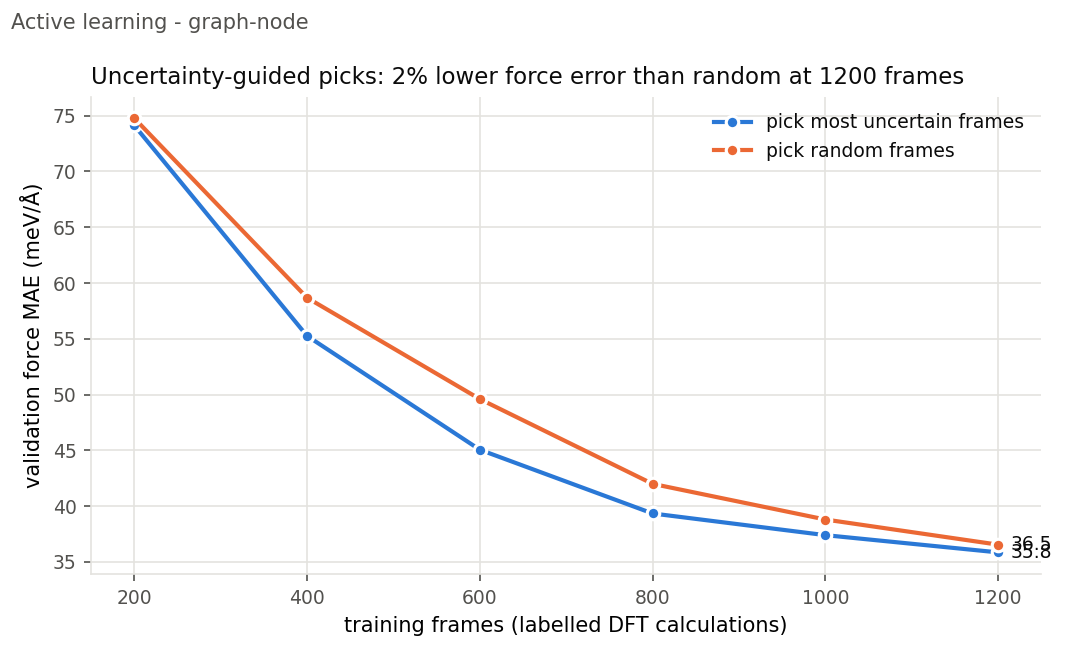

### MD early warning - `graph-node_seed1`

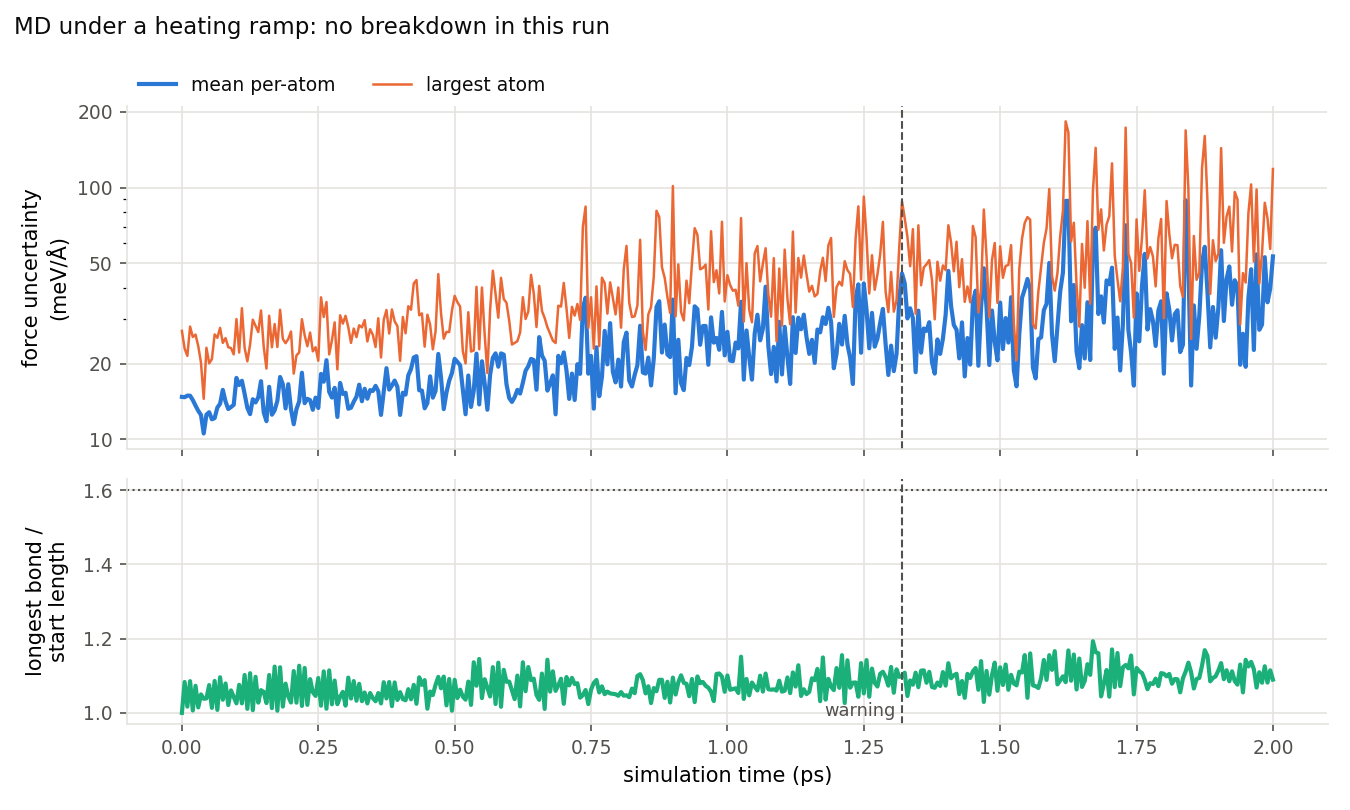

### Out-of-distribution test - `graph-both-env_seed1`

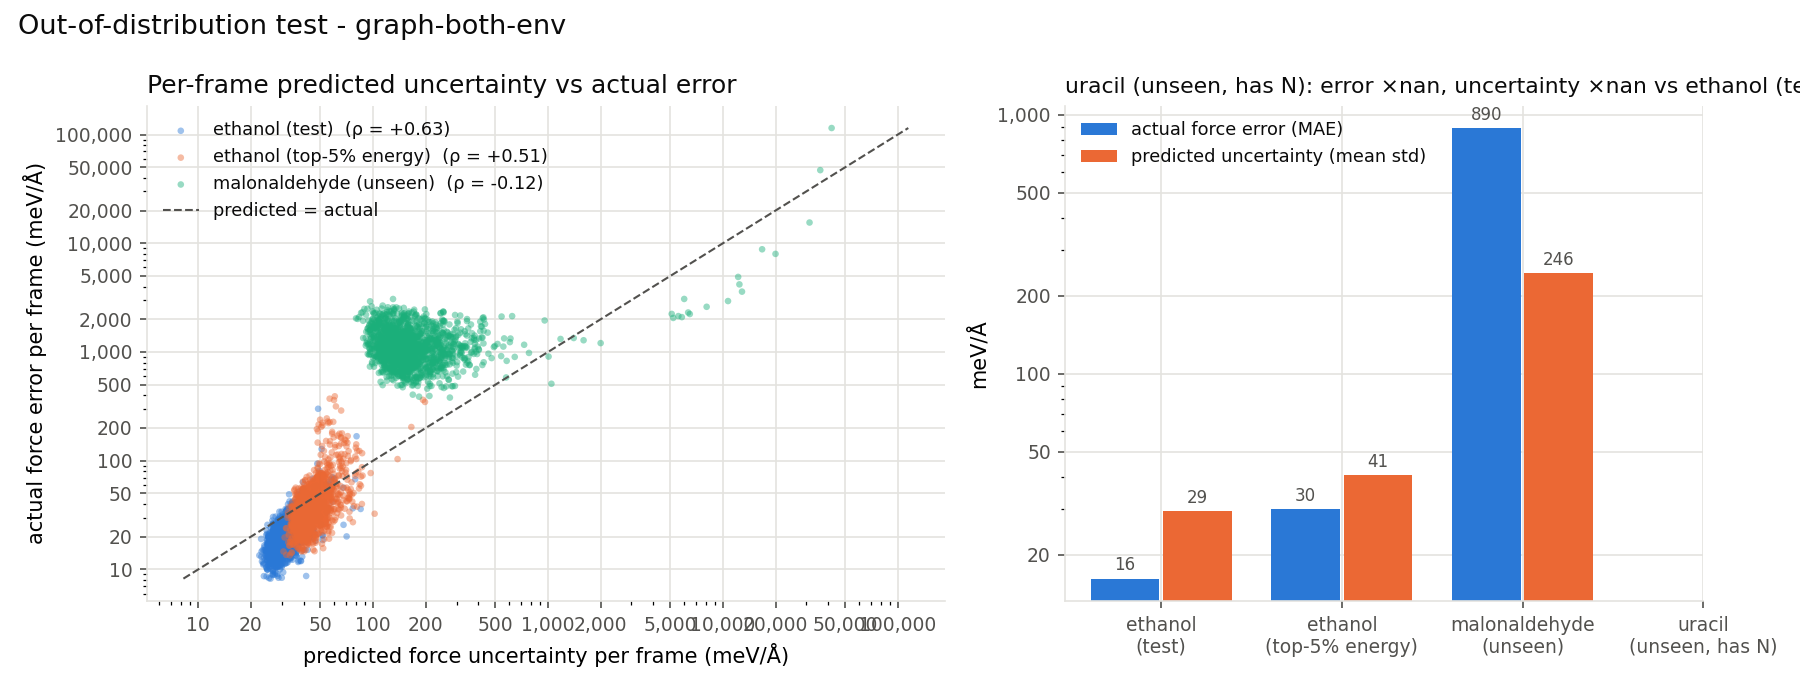

### Out-of-distribution test - `graph-both_seed1`

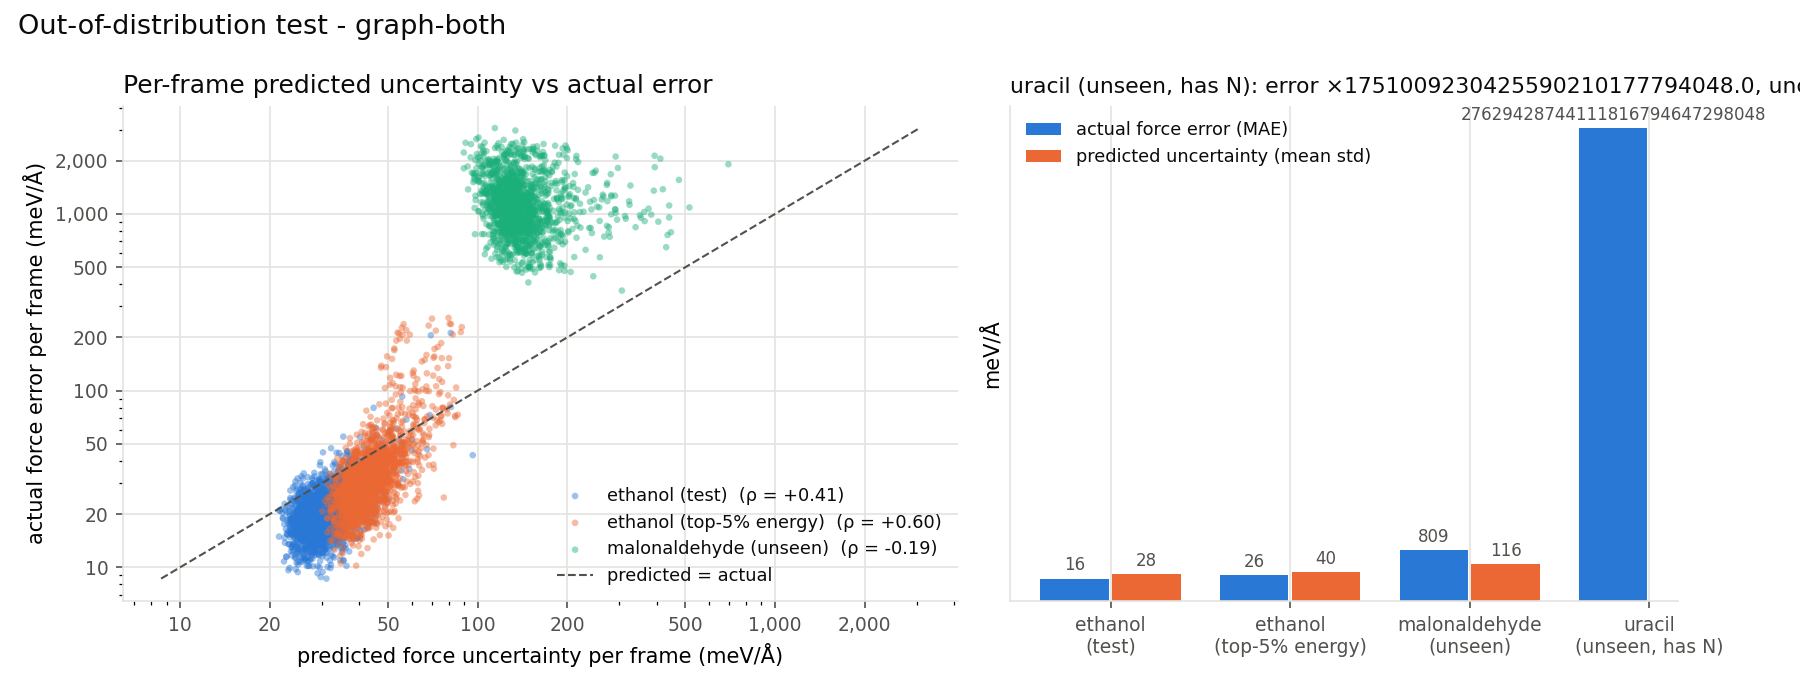

### Out-of-distribution test - `graph-edge_seed1`

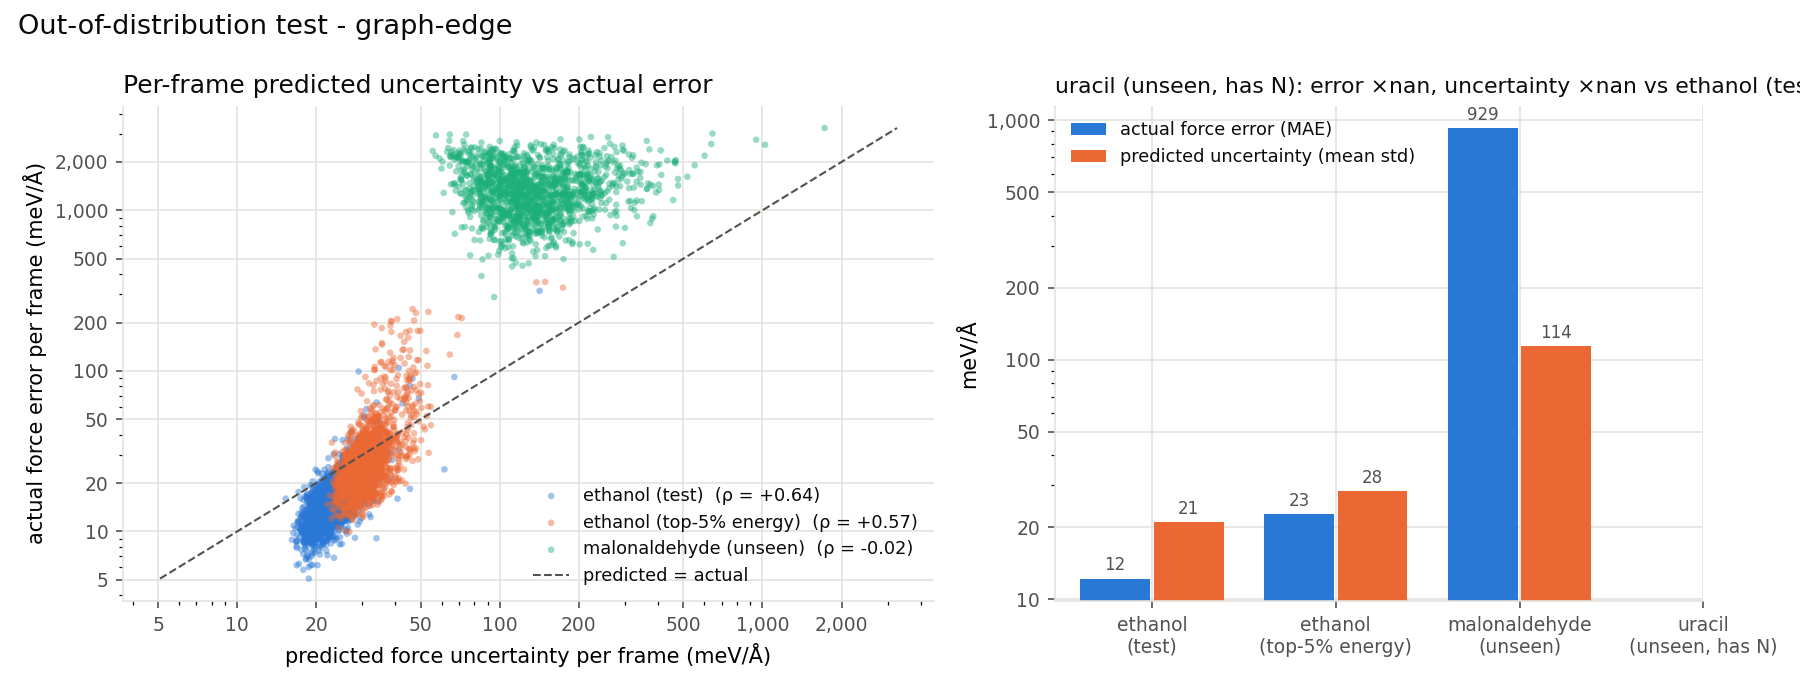

### Out-of-distribution test - `graph-node_seed1`

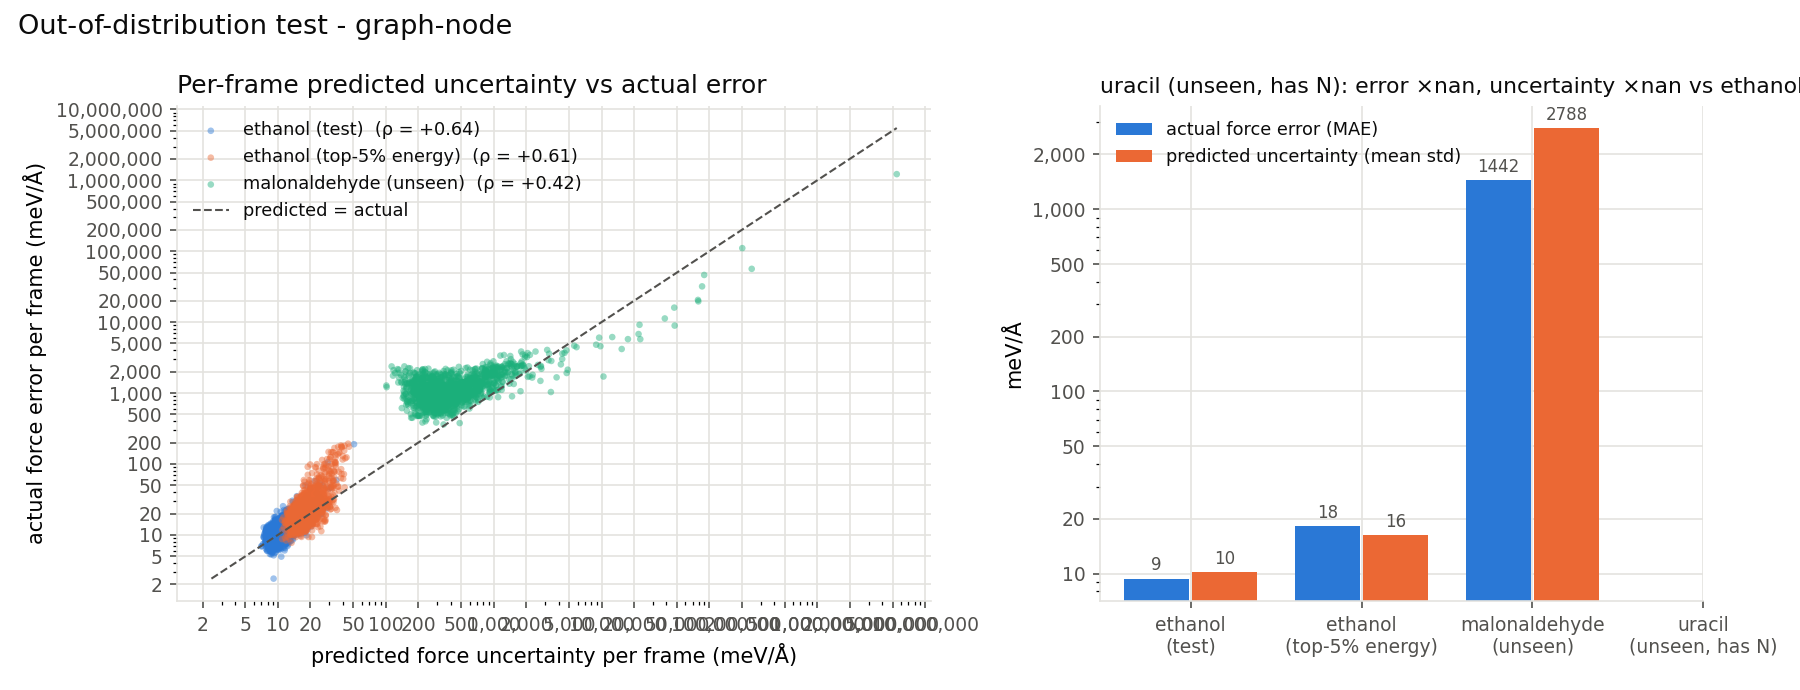

### Interactive 3D viewer (press Play, drag the slider, or click a timeline)

In [18]:
from IPython.display import Image, HTML, Markdown, display

TITLES = {"ood_": "Out-of-distribution test", "al_": "Active learning", "md_": "MD early warning"}

pngs = sorted(f for f in os.listdir(SHOW) if f.endswith(".png"))
if not pngs:
    print("No figures yet - run sections B, C and D first.")
for f in pngs:
    kind = next((t for p, t in TITLES.items() if f.startswith(p)), "Figure")
    model = f.rsplit(".", 1)[0].replace("gold_ethanol_dft_", "").split("_", 1)[-1]
    display(Markdown(f"### {kind} - `{model}`"))
    display(Image(filename=os.path.join(SHOW, f), width=1000))

viewer_path = os.path.join(SHOW, "md_viewer.html")
if os.path.exists(viewer_path):
    display(Markdown("### Interactive 3D viewer (press Play, drag the slider, or click a timeline)"))
    display(HTML(open(viewer_path, encoding="utf-8").read()))

In [1]:
import os
%env GIT_LFS_SKIP_SMUDGE=1
REPO = "/content/HydrogenProductionMaterials_Discovery"
if not os.path.exists(REPO):
    !git clone https://github.com/AlexTanui/HydrogenProductionMaterials_Discovery.git {REPO}
%cd {REPO}
!git fetch origin ruturaj-phase3-graph-stochastic
!git checkout -B ruturaj-phase3-graph-stochastic origin/ruturaj-phase3-graph-stochastic

env: GIT_LFS_SKIP_SMUDGE=1
Cloning into '/content/HydrogenProductionMaterials_Discovery'...
remote: Enumerating objects: 1724, done.
remote: Counting objects: 100% (690/690), done.
remote: Compressing objects: 100% (391/391), done.
remote: Total 1724 (delta 403), reused 486 (delta 297), pack-reused 1034 (from 1)
Receiving objects: 100% (1724/1724), 11.45 MiB | 9.35 MiB/s, done.
Resolving deltas: 100% (980/980), done.
/content/HydrogenProductionMaterials_Discovery
From https://github.com/AlexTanui/HydrogenProductionMaterials_Discovery
 * branch            ruturaj-phase3-graph-stochastic -> FETCH_HEAD
branch 'ruturaj-phase3-graph-stochastic' set up to track 'origin/ruturaj-phase3-graph-stochastic'.
Switched to a new branch 'ruturaj-phase3-graph-stochastic'
